# Book-level data and descriptive analysis

This publication notebook documents creation of the finalized one-row-per-book analysis table and the descriptive analyses used in the manuscript. The upstream reconstruction cells are retained for reproducibility but should only be rerun when intentionally rebuilding `book_summary_analysis.csv`. Routine descriptive work begins from the existing finalized CSV.

Manuscript outputs in this notebook are **Paper Figure 2** (overlapping indicator-group heatmaps) and **Paper Figure 7** (publication-year scatter and rolling trends). Other retained figures and summaries are supporting descriptive analyses.


In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("MPLCONFIGDIR", "/tmp/interiority_mplconfig")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

WORKING_DIR = Path.cwd()
ROOT = WORKING_DIR if (WORKING_DIR / "book_summary_analysis.csv").exists() else WORKING_DIR.parent
if not (ROOT / "book_summary_analysis.csv").exists():
    raise FileNotFoundError("Run this notebook from the repository root or analysis/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from analysis_utils import (
    BOOTSTRAP_REPETITIONS,
    BOOTSTRAP_SEED,
    BROAD_GROUP_COLORS,
    BROAD_GROUP_LABELS,
    BROAD_GROUP_MARKERS,
    BROAD_GROUP_ORDER,
    DOMESTIC_HYBRID_ORANGE,
    DOMESTIC_ORANGE,
    GENRE_COLUMNS,
    GENRE_LABELS,
    LIGHT_GRAY,
    NONDOMESTIC_BLUE,
    NONDOMESTIC_DARK,
    PERIOD_COLORS,
    PERIOD_MARKERS,
    PUBLICATION_PERIODS,
    RESIDUAL_GRAY,
    SUBSTANTIVE_GENRES,
    TIME_PERIOD_ORDER,
    bootstrap_difference_summary,
    bootstrap_mean_summary,
    configure_analysis_style,
    draw_period_estimate,
    rolling_book_bootstrap,
    save_figure,
)

BOOK_SUMMARY_PATH = ROOT / "combined_book_summary_with_candidates.csv"
ANALYSIS_TABLE_PATH = ROOT / "book_summary_analysis.csv"
ANALYSIS_SCHEMA_PATH = ROOT / "book_summary_analysis_schema.csv"

configure_analysis_style()


## Data preparation

> **Data preparation - only rerun when rebuilding the finalized book-level analysis dataset from upstream inputs.**
>
> The cells in this section preserve the existing preparation logic and write `book_summary_analysis.csv`. They require upstream inputs such as `combined_book_summary_with_candidates.csv` and `author_gender_missing.csv`, which are not needed for publication-notebook cleanup or routine analysis of the finalized dataset.


### Load and inspect the upstream combined book summary


In [27]:
book_summary = pd.read_csv(BOOK_SUMMARY_PATH, low_memory=False)

print(f"Loaded: {BOOK_SUMMARY_PATH.name}")
print(f"Rows: {len(book_summary):,}")
print(f"Columns: {book_summary.shape[1]:,}")
print(f"Distinct books: {book_summary['gutenberg_id'].nunique():,}")

display(book_summary.head())


Loaded: combined_book_summary_with_candidates.csv
Rows: 1,351
Columns: 95
Distinct books: 1,351


,gutenberg_id,scope,title,candidate_title,is_armstrong_indexed,inference_source,candidate_join_status,candidate_armstrong_flag_matches,narrative_mode,protagonist_gender,protagonist_structure,protagonist_analysis_status,overall_quote_share,n_narration_only,n_narration_dominant,n_quotation_dominant,n_quotation_only,high_mean_quote_share,low_mean_quote_share,none_mean_quote_share,n_narration_dominant_valid,n_quotation_dominant_valid,narration_quotation_interiority_gap,narration_quotation_high_rate_gap,high_narration_enrichment,is_core,n_requested,n_success,n_failed,none_count,low_count,high_count,none_pct,low_pct,high_pct,avg_interiority_score,publication_year,author_raw,author_display,author_query,gender,nationality,subjects,subject_text,is_domestic,is_detective_mystery,is_science_fiction,is_adventure,is_gothic,is_historical,has_major_genre,genre_tags,broad_group,author_key_normalized,author_display_normalized,is_canonical_author,canonical_period,is_english_fiction_19c,is_general_19c_candidate,auto_group,has_fiction_signal,wd_qid,wd_writer,match_rule,is_matched,resolution_status,is_manual_resolution,place,wd_birthYears,wd_deathYear,wd_gender,wd_tier,wd_all_tiers,wd_places,wd_is_uk,wd_colonial_only,author_exact_key,title_exact_key,exact_duplicate_rank,is_exact_duplicate,is_complete_edition,is_volume_part,has_multi_volume_phrase,volume_number,stated_total_volumes,volume_base_title,volume_base_title_key,is_volume_related,volume_family_key,author_book_count,decade,time_period,title_match_key,author_match_key,armstrong_category
0,84,base,Frankenstein,"Frankenstein; or, the modern prometheus",1,inference_vertex_minimal0728,both,True,mixed,male,single_dominant,included,0.437957,45,53,39,31,0.412472,0.443016,0.800000,53,39,0.164973,0.081277,0.025485,False,100,100,0,5,20,75,0.05,0.20,0.75,1.70,1818,"Shelley, Mary Wollstonecraft, 1797-1851",Mary Wollstonecraft Shelley,Mary Wollstonecraft Shelley,female,British,Science fiction; Horror tales; Gothic fiction;...,science fiction; horror tales; gothic fiction;...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,science_fiction; gothic,major_genre_non_domestic,mary wollstonecraft shelley,mary wollstonecraft shelley,1.0,Romantic,0.0,0.0,non_domestic_genre,True,http://www.wikidata.org/entity/Q47152,Mary Shelley,display:firstlast:year_ok,True,automatic_wikidata,False,Kingdom of Great Britain | United Kingdom | Un...,[1797],1851.0,female,core,['core'],"['Kingdom of Great Britain', 'United Kingdom',...",True,False,mary wollstonecraft shelley,"frankenstein; or, the modern prometheus",0.0,False,False,False,False,NaN,NaN,"Frankenstein; or, the modern prometheus",frankenstein or the modern prometheus,False,mary wollstonecraft shelley || frankenstein or...,8,1810.0,1810–1900,frankenstein the modern prometheus,mary wollstonecraft shelley,NaN
1,121,base,Northanger Abbey,Northanger Abbey,1,inference_vertex_minimal0728,both,True,third_person,female,single_dominant,included,0.513139,25,40,43,23,0.430382,0.628165,0.422581,40,43,0.277907,0.281395,0.082757,False,100,100,0,4,42,54,0.04,0.42,0.54,1.50,1818,"Austen, Jane, 1775-1817",Jane Austen,Jane Austen,female,British,England -- Social life and customs -- 19th cen...,england -- social life and customs -- 19th cen...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,gothic,major_genre_non_domestic,jane austen,jane austen,1.0,Romantic,0.0,0.0,non_domestic_genre,True,http://www.wikidata.org/entity/Q36322,Jane Austen,display:exact:year_ok,True,automatic_wikidata,False,United Kingdom of Great Britain and Ireland,[1775],1817.0,female,core,['core'],['United Kingdom of Great Britain and Ireland'],True,False,jane austen,northanger abbey,0.0,False,False,False,False,NaN,NaN,Northanger Abbey,northanger abbey,False,jane austen || northanger abbey,9,1810.0,1810–1900,northanger abbey,jane austen,NaN
2,141,base,Mansfield Park,Mansfield Park,1,inference_vertex_minimal0728,both,True,third_person,female,single_dominant,included,0.451546,39,46,40,14,0.383042,0.570975,0.475188,46,40,0.267391,0.235870,0.068505,False,100,100,0

### Inspect available upstream columns


In [28]:
column_list = book_summary.columns.tolist()

for position, column in enumerate(column_list, start=1):
    print(f"{position:>2}. {column}")


 1. gutenberg_id
 2. scope
 3. title
 4. candidate_title
 5. is_armstrong_indexed
 6. inference_source
 7. candidate_join_status
 8. candidate_armstrong_flag_matches
 9. narrative_mode
10. protagonist_gender
11. protagonist_structure
12. protagonist_analysis_status
13. overall_quote_share
14. n_narration_only
15. n_narration_dominant
16. n_quotation_dominant
17. n_quotation_only
18. high_mean_quote_share
19. low_mean_quote_share
20. none_mean_quote_share
21. n_narration_dominant_valid
22. n_quotation_dominant_valid
23. narration_quotation_interiority_gap
24. narration_quotation_high_rate_gap
25. high_narration_enrichment
26. is_core
27. n_requested
28. n_success
29. n_failed
30. none_count
31. low_count
32. high_count
33. none_pct
34. low_pct
35. high_pct
36. avg_interiority_score
37. publication_year
38. author_raw
39. author_display
40. author_query
41. gender
42. nationality
43. subjects
44. subject_text
45. is_domestic
46. is_detective_mystery
47. is_science_fiction
48. is_adventur

In [29]:
column_schema = pd.DataFrame(
    {
        "position": range(1, len(book_summary.columns) + 1),
        "column": book_summary.columns,
        "dtype": book_summary.dtypes.astype(str).values,
        "non_missing": book_summary.notna().sum().values,
        "missing": book_summary.isna().sum().values,
        "unique_values": book_summary.nunique(dropna=True).values,
    }
)

display(column_schema)


,position,column,dtype,non_missing,missing,unique_values
0,1,gutenberg_id,int64,1351,0,1351
1,2,scope,object,1351,0,1
2,3,title,object,1351,0,1350
3,4,candidate_title,object,1351,0,1350
4,5,is_armstrong_indexed,int64,1351,0,2
5,6,inference_source,object,1351,0,3
6,7,candidate_join_status,object,1351,0,1
7,8,candidate_armstrong_flag_matches,bool,1351,0,1
8,9,narrative_mode,object,1351,0,7
9,10,protagonist_gender,object,1351,0,7


The printed list provides the exact column order. The schema table adds data types, missingness, and unique-value counts so that the next analysis can select suitable identifiers, outcomes, and metadata fields.


### Build and save the focused finalized book-summary table


In [30]:
SELECTED_BOOK_COLUMNS = [
    "gutenberg_id",
    "title",
    "publication_year",
    "author_display",
    "author_query",
    "gender",
    "narrative_mode",
    "protagonist_gender",
    "protagonist_structure",
    "protagonist_analysis_status",
    "is_armstrong_indexed",
    "avg_interiority_score",
    "none_count",
    "low_count",
    "high_count",
    "none_pct",
    "low_pct",
    "high_pct",
    "is_domestic",
    "is_detective_mystery",
    "is_science_fiction",
    "is_adventure",
    "is_gothic",
    "is_historical",
    "has_major_genre",
    "genre_tags",
    "broad_group",
    "is_canonical_author",
    "canonical_period",
    "is_english_fiction_19c",
    "auto_group",
    "is_volume_part",
    "author_book_count",
    "decade",
    "time_period",
    "title_match_key",
    "author_match_key",
    "is_core",
    "overall_quote_share",
    "n_narration_only",
    "n_narration_dominant",
    "n_quotation_dominant",
    "n_quotation_only",
    "narration_quotation_interiority_gap",
    "narration_quotation_high_rate_gap",
    "high_narration_enrichment",
    "subject_text"

]

missing_requested_columns = [
    column for column in SELECTED_BOOK_COLUMNS if column not in book_summary.columns
]
if missing_requested_columns:
    raise KeyError(f"Requested columns not found: {missing_requested_columns}")

book_summary_analysis = (
    book_summary.loc[:, SELECTED_BOOK_COLUMNS]
    .rename(columns={"gender": "author_gender"})
    .copy()
)

# Remove three duplicate Dickens records, then standardize the remaining
# abbreviated author name before downstream joins and author-level summaries.
DICKENS_DUPLICATE_GUTENBERG_IDS = {61193, 810, 676}
gutenberg_id_numeric = pd.to_numeric(
    book_summary_analysis["gutenberg_id"], errors="coerce"
)
dickens_duplicate_mask = gutenberg_id_numeric.isin(
    DICKENS_DUPLICATE_GUTENBERG_IDS
)
removed_dickens_ids = sorted(
    gutenberg_id_numeric.loc[dickens_duplicate_mask].dropna().astype(int).tolist()
)
if set(removed_dickens_ids) != DICKENS_DUPLICATE_GUTENBERG_IDS:
    raise ValueError(
        "Expected to remove Dickens Gutenberg IDs "
        f"{sorted(DICKENS_DUPLICATE_GUTENBERG_IDS)}, found "
        f"{removed_dickens_ids}."
    )

book_summary_analysis = (
    book_summary_analysis.loc[~dickens_duplicate_mask].copy()
)
book_summary_analysis.loc[
    book_summary_analysis["author_display"].eq("Dickens"),
    "author_display",
] = "Charles Dickens"

# The analysis table has changed, so keep author_book_count aligned with the
# current one-row-per-book dataset rather than carrying forward source counts.
book_summary_analysis["author_book_count"] = (
    book_summary_analysis.groupby("author_query", dropna=False)["gutenberg_id"]
    .transform("nunique")
    .astype("Int64")
)
print(
    f"Removed Dickens duplicate Gutenberg IDs: {removed_dickens_ids}; "
    "standardized remaining author_display values to Charles Dickens."
)

AUTHOR_GENDER_MISSING_PATH = ROOT / "author_gender_missing.csv"
author_gender_missing = (
    pd.read_csv(AUTHOR_GENDER_MISSING_PATH)
    .rename(
        columns={
            "author": "author_display",
            "gender": "author_gender_fill",
        }
    )
)
required_gender_fill_columns = {"author_display", "author_gender_fill"}
if not required_gender_fill_columns.issubset(author_gender_missing.columns):
    raise KeyError(
        "author_gender_missing.csv must contain author and gender columns."
    )
if author_gender_missing["author_display"].duplicated().any():
    duplicate_authors = author_gender_missing.loc[
        author_gender_missing["author_display"].duplicated(keep=False),
        "author_display",
    ].unique()
    raise ValueError(
        "Duplicate authors in author_gender_missing.csv: "
        f"{duplicate_authors.tolist()}"
    )

author_gender_missing_before = int(
    book_summary_analysis["author_gender"].isna().sum()
)
book_summary_analysis = book_summary_analysis.merge(
    author_gender_missing,
    on="author_display",
    how="left",
    validate="many_to_one",
)
book_summary_analysis["author_gender"] = (
    book_summary_analysis["author_gender"].fillna(
        book_summary_analysis["author_gender_fill"]
    )
)
book_summary_analysis = book_summary_analysis.drop(
    columns="author_gender_fill"
)
author_gender_missing_after = int(
    book_summary_analysis["author_gender"].isna().sum()
)
print(
    f"Filled {author_gender_missing_before - author_gender_missing_after:,} "
    f"previously missing author_gender records from "
    f"{AUTHOR_GENDER_MISSING_PATH.name}; "
    f"{author_gender_missing_after:,} remain missing."
)
book_summary_analysis["protagonist_gender"] = (
    book_summary_analysis["protagonist_gender"].replace(
        {
            "female": "F",
            "male": "M",
        }
    )
)

book_summary_analysis["broad_group_analysis"] = (
    book_summary_analysis["broad_group"].replace(
        {
            "domestic_only": "all_domestic",
            "domestic_and_genre": "all_domestic",
        }
    )
)

BROAD_GROUP_ANALYSIS_ORDER = [
    "all_domestic",
    "major_genre_non_domestic",
    "other_non_domestic_non_major_genre",
    "missing",
]
BROAD_GROUP_ANALYSIS_LABELS = {
    "all_domestic": "All domestic",
    "major_genre_non_domestic": BROAD_GROUP_LABELS["major_genre_non_domestic"],
    "other_non_domestic_non_major_genre": BROAD_GROUP_LABELS[
        "other_non_domestic_non_major_genre"
    ],
    "missing": BROAD_GROUP_LABELS["missing"],
}
BROAD_GROUP_ANALYSIS_COLORS = {
    "all_domestic": BROAD_GROUP_COLORS["domestic_only"],
    "major_genre_non_domestic": BROAD_GROUP_COLORS["major_genre_non_domestic"],
    "other_non_domestic_non_major_genre": BROAD_GROUP_COLORS[
        "other_non_domestic_non_major_genre"
    ],
    "missing": BROAD_GROUP_COLORS["missing"],
}
BROAD_GROUP_ANALYSIS_MARKERS = {
    "all_domestic": BROAD_GROUP_MARKERS["domestic_only"],
    "major_genre_non_domestic": BROAD_GROUP_MARKERS["major_genre_non_domestic"],
    "other_non_domestic_non_major_genre": BROAD_GROUP_MARKERS[
        "other_non_domestic_non_major_genre"
    ],
    "missing": BROAD_GROUP_MARKERS["missing"],
}

book_summary_analysis["time_period"] = pd.cut(
    pd.to_numeric(
        book_summary_analysis["publication_year"],
        errors="coerce",
    ),
    bins=[float("-inf"), 1840, 1900, float("inf")],
    labels=TIME_PERIOD_ORDER,
    right=False,
    ordered=True,
)

book_summary_analysis.to_csv(ANALYSIS_TABLE_PATH, index=False)
book_summary_analysis_schema = pd.DataFrame(
    {
        "position": range(1, len(book_summary_analysis.columns) + 1),
        "column": book_summary_analysis.columns,
        "dtype": book_summary_analysis.dtypes.astype(str).values,
        "non_missing": book_summary_analysis.notna().sum().values,
        "missing": book_summary_analysis.isna().sum().values,
        "unique_values": book_summary_analysis.nunique(dropna=True).values,
    }
)
book_summary_analysis_schema.to_csv(ANALYSIS_SCHEMA_PATH, index=False)

print(f"Saved downstream analysis table: {ANALYSIS_TABLE_PATH}")
print(f"Saved analysis-table schema: {ANALYSIS_SCHEMA_PATH}")

print(f"Rows: {len(book_summary_analysis):,}")
print(f"Columns retained: {book_summary_analysis.shape[1]}")
print(f"Distinct books: {book_summary_analysis['gutenberg_id'].nunique():,}")
display(book_summary_analysis.head())


Removed Dickens duplicate Gutenberg IDs: [676, 810, 61193]; standardized remaining author_display values to Charles Dickens.
Filled 90 previously missing author_gender records from author_gender_missing.csv; 0 remain missing.
Saved downstream analysis table: /Users/chelseachen/Desktop/interiority/book_summary_analysis.csv
Saved analysis-table schema: /Users/chelseachen/Desktop/interiority/book_summary_analysis_schema.csv
Rows: 1,348
Columns retained: 48
Distinct books: 1,348


,gutenberg_id,title,publication_year,author_display,author_query,author_gender,narrative_mode,protagonist_gender,protagonist_structure,protagonist_analysis_status,is_armstrong_indexed,avg_interiority_score,none_count,low_count,high_count,none_pct,low_pct,high_pct,is_domestic,is_detective_mystery,is_science_fiction,is_adventure,is_gothic,is_historical,has_major_genre,genre_tags,broad_group,is_canonical_author,canonical_period,is_english_fiction_19c,auto_group,is_volume_part,author_book_count,decade,time_period,title_match_key,author_match_key,is_core,overall_quote_share,n_narration_only,n_narration_dominant,n_quotation_dominant,n_quotation_only,narration_quotation_interiority_gap,narration_quotation_high_rate_gap,high_narration_enrichment,subject_text,broad_group_analysis
0,84,Frankenstein,1818,Mary Wollstonecraft Shelley,Mary Wollstonecraft Shelley,female,mixed,M,single_dominant,included,1,1.70,5,20,75,0.05,0.20,0.75,0.0,0.0,1.0,0.0,1.0,0.0,1.0,science_fiction; gothic,major_genre_non_domestic,1.0,Romantic,0.0,non_domestic_genre,False,8,1810.0,<1840,frankenstein the modern prometheus,mary wollstonecraft shelley,False,0.437957,45,53,39,31,0.164973,0.081277,0.025485,science fiction; horror tales; gothic fiction;...,major_genre_non_domestic
1,121,Northanger Abbey,1818,Jane Austen,Jane Austen,female,third_person,F,single_dominant,included,1,1.50,4,42,54,0.04,0.42,0.54,0.0,0.0,0.0,0.0,1.0,0.0,1.0,gothic,major_genre_non_domestic,1.0,Romantic,0.0,non_domestic_genre,False,9,1810.0,<1840,northanger abbey,jane austen,False,0.513139,25,40,43,23,0.277907,0.281395,0.082757,england -- social life and customs -- 19th cen...,major_genre_non_domestic
2,141,Mansfield Park,1814,Jane Austen,Jane Austen,female,third_person,F,single_dominant,included,1,1.56,5,34,61,0.05,0.34,0.61,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,domestic_only,1.0,Romantic,0.0,core_domestic,False,9,1810.0,<1840,mansfield park,jane austen,False,0.451546,39,46,40,14,0.267391,0.235870,0.068505,england -- fiction; young women -- fiction; lo...,all_domestic
3,145,Middlemarch,1871,George Eliot,George Eliot,female,third_person,mixed,mixed_gender,included,1,1.37,7,49,44,0.07,0.49,0.44,1.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,domestic_only,1.0,Victorian,0.0,core_domestic,False,9,1870.0,1840-1899,middlemarch,george eliot,False,0.447320,28,40,30,7,0.400000,0.433333,0.166880,didactic fiction; city and town life -- fictio...,all_domestic
4,158,Emma,1815,Jane Austen,Jane Austen,female,third_person,F,single_dominant,included,1,1.43,6,45,49,0.06,0.45,0.49,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,other_non_domestic_non_major_genre,1.0,Romantic,0.0,canonical_other,False,9,1810.0,<1840,emma,jane austen,True,0.502222,37,44,45,21,0.212626,0.259091,0.123004,humorous stories; england -- fiction; young wo...,other_non_domestic_non_major_genre


`book_summary_analysis` is the finalized one-row-per-book table used below. It is exported as
`book_summary_analysis.csv`; later notebooks load that file directly rather than rebuilding the selection.


## Corpus and descriptive analyses

The remaining sections load the existing finalized `book_summary_analysis.csv` directly. They do not rebuild or modify it.


In [2]:
book_summary_analysis = pd.read_csv(ANALYSIS_TABLE_PATH, low_memory=False)
if book_summary_analysis["gutenberg_id"].duplicated().any():
    raise ValueError("Descriptive analyses require exactly one row per book.")
print(f"Loaded finalized analysis table: {ANALYSIS_TABLE_PATH}")
print(f"Rows: {len(book_summary_analysis):,}; distinct books: {book_summary_analysis['gutenberg_id'].nunique():,}")


Loaded finalized analysis table: /Users/michellelin/Desktop/interiority/ACH-submission/Interiority/book_summary_analysis.csv
Rows: 1,348; distinct books: 1,348


### Overall interiority-score distribution

The distribution uses one base-sample score per book. Missing book scores are counted explicitly and excluded from numerical summaries and the histogram.


,metric,value
0,all_books,1348.000
1,books_with_score,1348.000
2,books_missing_score,0.000
3,mean,1.077
4,standard_deviation,0.220
5,minimum,0.240
6,5th_percentile,0.710
7,25th_percentile,0.920
8,median,1.080
9,75th_percentile,1.230


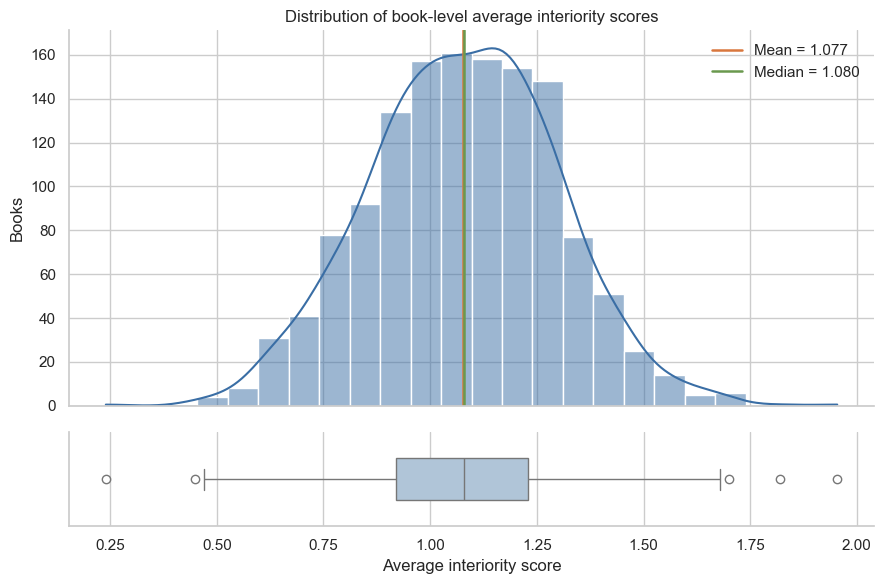

In [31]:
score = book_summary_analysis["avg_interiority_score"].dropna()

overall_score_summary = pd.DataFrame(
    {
        "metric": [
            "all_books",
            "books_with_score",
            "books_missing_score",
            "mean",
            "standard_deviation",
            "minimum",
            "5th_percentile",
            "25th_percentile",
            "median",
            "75th_percentile",
            "95th_percentile",
            "maximum",
        ],
        "value": [
            len(book_summary_analysis),
            score.count(),
            book_summary_analysis["avg_interiority_score"].isna().sum(),
            score.mean(),
            score.std(),
            score.min(),
            score.quantile(0.05),
            score.quantile(0.25),
            score.median(),
            score.quantile(0.75),
            score.quantile(0.95),
            score.max(),
        ],
    }
)
display(overall_score_summary.style.format({"value": "{:.3f}"}))

fig, axes = plt.subplots(
    2,
    1,
    figsize=(9, 6),
    gridspec_kw={"height_ratios": [4, 1]},
    sharex=True,
)
sns.histplot(
    score,
    bins=24,
    kde=True,
    color="#3A6EA5",
    ax=axes[0],
)
axes[0].axvline(
    score.mean(),
    color="#D9773D",
    linewidth=1.8,
    label=f"Mean = {score.mean():.3f}",
)
axes[0].axvline(
    score.median(),
    color="#6A994E",
    linewidth=1.8,
    label=f"Median = {score.median():.3f}",
)
axes[0].set_title("Distribution of book-level average interiority scores")
axes[0].set_ylabel("Books")
axes[0].legend(frameon=False)

sns.boxplot(
    x=score,
    color="#A9C5DF",
    width=0.45,
    ax=axes[1],
)
axes[1].set_xlabel("Average interiority score")
axes[1].set_ylabel("")
for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()


### Highest and lowest five books


In [32]:
ranked_books = (
    book_summary_analysis.dropna(subset=["avg_interiority_score"])
    .sort_values(
        ["avg_interiority_score", "title", "gutenberg_id"],
        ascending=[False, True, True],
    )
)
book_rank_columns = [
    "gutenberg_id",
    "title",
    "author_display",
    "publication_year",
    "broad_group",
    "avg_interiority_score",
    "genre_tags"
]
highest_five_books = ranked_books[book_rank_columns].head(5)
lowest_five_books = (
    ranked_books.sort_values(
        ["avg_interiority_score", "title", "gutenberg_id"],
        ascending=[True, True, True],
    )[book_rank_columns]
    .head(5)
)

display(Markdown("**Highest five books**"))
display(highest_five_books.style.format({"avg_interiority_score": "{:.3f}"}))
display(Markdown("**Lowest five books**"))
display(lowest_five_books.style.format({"avg_interiority_score": "{:.3f}"}))


**Highest five books**

,gutenberg_id,title,author_display,publication_year,broad_group,avg_interiority_score,genre_tags
13,946,Lady Susan,Jane Austen,1871,other_non_domestic_non_major_genre,1.954,nan
804,4046,The Garden of Survival,Algernon Blackwood,1922,major_genre_non_domestic,1.820,gothic
0,84,Frankenstein,Mary Wollstonecraft Shelley,1818,major_genre_non_domestic,1.700,science_fiction; gothic
223,9299,"Italian Letters, Vols. I and II; Or, The History of the Count de St. Julian",William Godwin,1802,other_non_domestic_non_major_genre,1.680,nan
294,16357,Mary: A Fiction,Mary Wollstonecraft,1798,other_non_domestic_non_major_genre,1.680,nan


**Lowest five books**

,gutenberg_id,title,author_display,publication_year,broad_group,avg_interiority_score,genre_tags
1332,78126,The weird of the wanderer,Frederick Rolfe,1912,major_genre_non_domestic,0.240,science_fiction
926,20641,"Through Three Campaigns: A Story of Chitral, Tirah and Ashanti",G. A. Henty,1890,major_genre_non_domestic,0.450,adventure
396,27993,Bruin: The Grand Bear Hunt,Mayne Reid,1870,major_genre_non_domestic,0.470,adventure
1238,69476,Account of an expedition to the interior of New Holland,Mary Fox,1837,major_genre_non_domestic,0.480,science_fiction
1343,79003,Last and first men,Olaf Stapledon,1930,major_genre_non_domestic,0.480,science_fiction


### Broad-group summary


In [33]:
broad_group_overall_summary = (
    book_summary_analysis.assign(
        broad_group_summary=book_summary_analysis["broad_group"].fillna("missing")
    )
    .groupby("broad_group_summary", as_index=False)
    .agg(
        books=("gutenberg_id", "nunique"),
        books_with_score=("avg_interiority_score", "count"),
        average_interiority=("avg_interiority_score", "mean"),
    )
)
broad_group_overall_summary["book_share"] = (
    broad_group_overall_summary["books"]
    / broad_group_overall_summary["books"].sum()
)

display(
    broad_group_overall_summary.sort_values(
        "books", ascending=False
    ).style.format(
        {
            "average_interiority": "{:.3f}",
            "book_share": "{:.1%}",
        }
    )
)


,broad_group_summary,books,books_with_score,average_interiority,book_share
2,major_genre_non_domestic,682,682,0.984,50.6%
1,domestic_only,428,428,1.193,31.8%
3,other_non_domestic_non_major_genre,199,199,1.132,14.8%
0,domestic_and_genre,39,39,1.164,2.9%


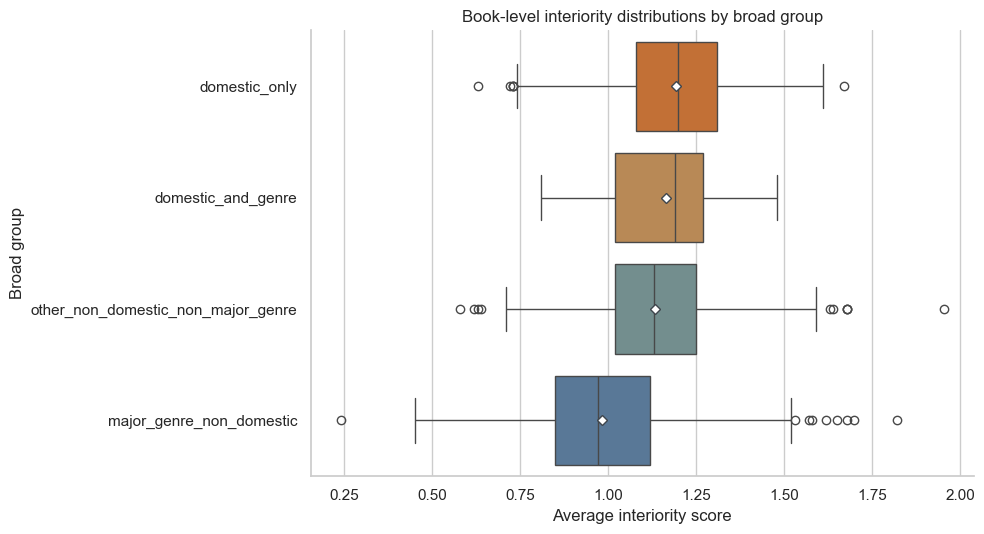

In [34]:
broad_group_boxplot_data = (
    book_summary_analysis.assign(
        broad_group_plot=book_summary_analysis["broad_group"].fillna("missing")
    )
    .dropna(subset=["avg_interiority_score"])
)
broad_group_box_order = (
    broad_group_overall_summary.sort_values(
        ["average_interiority", "broad_group_summary"],
        ascending=[False, True],
        na_position="last",
    )["broad_group_summary"].tolist()
)

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(
    data=broad_group_boxplot_data,
    x="avg_interiority_score",
    y="broad_group_plot",
    hue="broad_group_plot",
    order=broad_group_box_order,
    hue_order=broad_group_box_order,
    palette=BROAD_GROUP_COLORS,
    dodge=False,
    legend=False,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "white",
        "markeredgecolor": "#3F464D",
        "markersize": 5.5,
    },
    ax=ax,
)
ax.set_title("Book-level interiority distributions by broad group")
ax.set_xlabel("Average interiority score")
ax.set_ylabel("Broad group")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


### Overlapping indicator-group summary


In [35]:
SUMMARY_INDICATOR_COLUMNS = [
    "is_domestic",
    "is_detective_mystery",
    "is_science_fiction",
    "is_adventure",
    "is_gothic",
    "is_historical",
    "is_canonical_author",
    "is_english_fiction_19c",
]
SUMMARY_INDICATOR_LABELS = {
    "is_domestic": "Domestic",
    "is_detective_mystery": "Detective / mystery",
    "is_science_fiction": "Science fiction",
    "is_adventure": "Adventure",
    "is_gothic": "Gothic",
    "is_historical": "Historical",
    "is_canonical_author": "Canonical author",
    "is_english_fiction_19c": "English fiction, 19th c.",
}

indicator_overall_rows = []
for group_column in SUMMARY_INDICATOR_COLUMNS:
    group_books = (
        book_summary_analysis[
            ["gutenberg_id", "avg_interiority_score", group_column]
        ]
        .dropna(subset=[group_column])
        .loc[lambda frame: frame[group_column].eq(1)]
    )
    indicator_overall_rows.append(
        {
            "group_column": group_column,
            "group_label": SUMMARY_INDICATOR_LABELS[group_column],
            "books": group_books["gutenberg_id"].nunique(),
            "books_with_score": group_books["avg_interiority_score"].count(),
            "average_interiority": group_books["avg_interiority_score"].mean(),
        }
    )

indicator_overall_summary = pd.DataFrame(indicator_overall_rows)
display(
    indicator_overall_summary.style.format(
        {"average_interiority": "{:.3f}"}
    )
)


,group_column,group_label,books,books_with_score,average_interiority
0,is_domestic,Domestic,467,467,1.191
1,is_detective_mystery,Detective / mystery,212,212,0.978
2,is_science_fiction,Science fiction,63,63,1.010
3,is_adventure,Adventure,251,251,0.939
4,is_gothic,Gothic,76,76,1.176
5,is_historical,Historical,164,164,1.016
6,is_canonical_author,Canonical author,218,218,1.147
7,is_english_fiction_19c,"English fiction, 19th c.",112,112,1.103


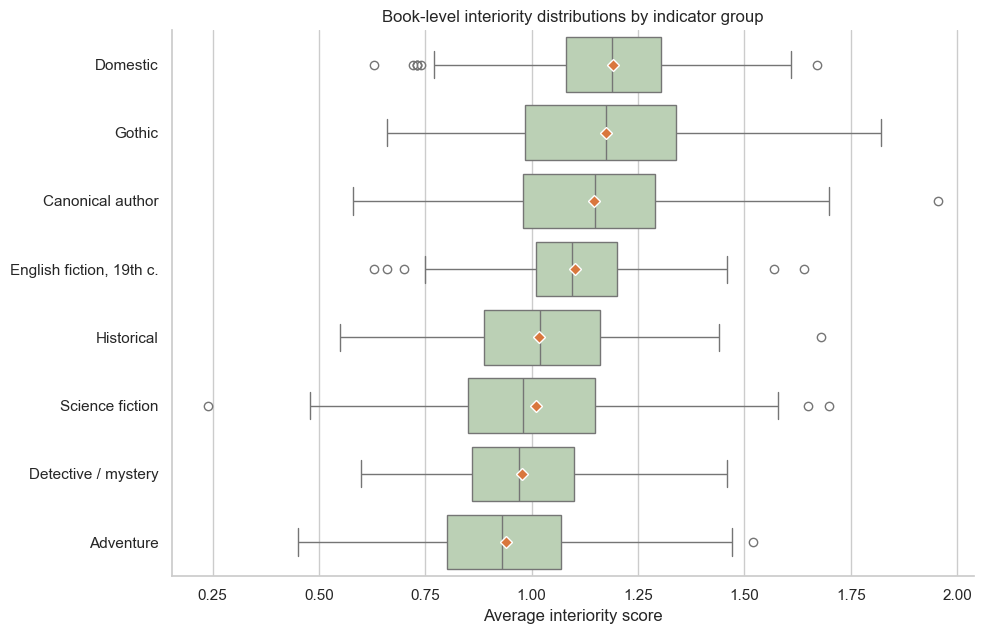

In [36]:
indicator_boxplot_frames = []
for group_column in SUMMARY_INDICATOR_COLUMNS:
    group_scores = (
        book_summary_analysis[
            ["gutenberg_id", "avg_interiority_score", group_column]
        ]
        .dropna(subset=["avg_interiority_score", group_column])
        .loc[lambda frame: frame[group_column].eq(1)]
        .copy()
    )
    group_scores["group_label"] = SUMMARY_INDICATOR_LABELS[group_column]
    indicator_boxplot_frames.append(group_scores)

indicator_boxplot_data = pd.concat(
    indicator_boxplot_frames,
    ignore_index=True,
)
indicator_box_order = (
    indicator_overall_summary.sort_values(
        ["average_interiority", "group_label"],
        ascending=[False, True],
        na_position="last",
    )["group_label"].tolist()
)

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.boxplot(
    data=indicator_boxplot_data,
    x="avg_interiority_score",
    y="group_label",
    order=indicator_box_order,
    color="#B8D5B0",
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": "#D9773D",
        "markeredgecolor": "white",
        "markersize": 6,
    },
    ax=ax,
)
ax.set_title("Book-level interiority distributions by indicator group")
ax.set_xlabel("Average interiority score")
ax.set_ylabel("")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


The eight indicator groups overlap, so their book counts should not be added together. All subgroup means are equal-book averages and automatically exclude missing book-level scores.


### Narrative-mode-base summary

`narrative_mode_base` consolidates candidate and reviewed narrative-mode labels into three broader descriptive categories.


In [37]:
NARRATIVE_MODE_BASE_MAP = {
    "third_person": "third_person",
    "third_person_candidate": "third_person",
    "epistolary": "epistolary",
    "epistolary_candidate": "epistolary",
    "first_person": "first_person_or_mixed",
    "first_person_candidate": "first_person_or_mixed",
    "mixed": "first_person_or_mixed",
}
book_summary_analysis["narrative_mode_base"] = (
    book_summary_analysis["narrative_mode"].replace(NARRATIVE_MODE_BASE_MAP)
)

narrative_mode_base_summary = (
    book_summary_analysis.assign(
        narrative_mode_base_summary=book_summary_analysis[
            "narrative_mode_base"
        ].fillna("missing")
    )
    .groupby("narrative_mode_base_summary", as_index=False)
    .agg(
        books=("gutenberg_id", "nunique"),
        books_with_score=("avg_interiority_score", "count"),
        average_interiority=("avg_interiority_score", "mean"),
    )
)
narrative_mode_base_summary["book_share"] = (
    narrative_mode_base_summary["books"]
    / narrative_mode_base_summary["books"].sum()
)

display(
    narrative_mode_base_summary.sort_values(
        ["books", "narrative_mode_base_summary"],
        ascending=[False, True],
    ).style.format(
        {
            "average_interiority": "{:.3f}",
            "book_share": "{:.1%}",
        }
    )
)


,narrative_mode_base_summary,books,books_with_score,average_interiority,book_share
2,third_person,964,964,1.069,71.5%
1,first_person_or_mixed,360,360,1.085,26.7%
0,epistolary,24,24,1.282,1.8%


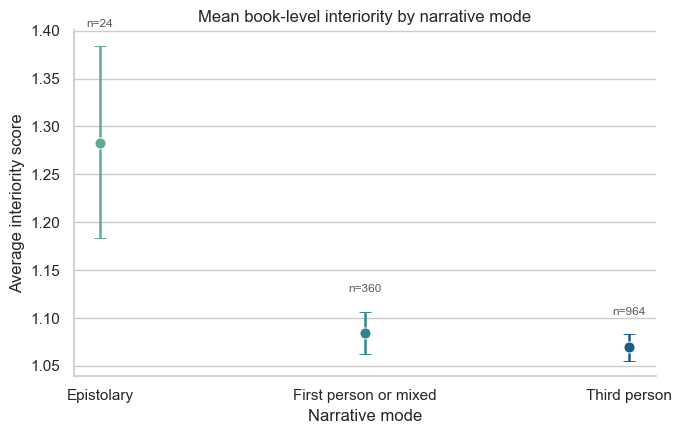

Points are equal-book means; whiskers are 95% book-level bootstrap CIs based on **5,000** resamples with a fixed seed.

In [38]:
narrative_mode_base_plot_data = (
    book_summary_analysis.assign(
        narrative_mode_base_plot=book_summary_analysis[
            "narrative_mode_base"
        ].fillna("missing")
    )
    .dropna(subset=["avg_interiority_score"])
)

narrative_mode_bootstrap_rows = []
for mode, mode_data in narrative_mode_base_plot_data.groupby(
    "narrative_mode_base_plot",
    sort=False,
):
    summary = bootstrap_mean_summary(
        mode_data["avg_interiority_score"],
        "narrative_mode_base",
        mode,
    )
    narrative_mode_bootstrap_rows.append(
        {
            "narrative_mode_base": mode,
            **summary,
        }
    )

narrative_mode_base_bootstrap = (
    pd.DataFrame(narrative_mode_bootstrap_rows)
    .sort_values(
        ["estimate", "narrative_mode_base"],
        ascending=[False, True],
        na_position="last",
    )
    .reset_index(drop=True)
)
narrative_mode_base_order = narrative_mode_base_bootstrap[
    "narrative_mode_base"
].tolist()
narrative_mode_base_palette = dict(
    zip(
        narrative_mode_base_order,
        sns.color_palette(
            "crest",
            n_colors=len(narrative_mode_base_order),
        ),
    )
)
if "missing" in narrative_mode_base_palette:
    narrative_mode_base_palette["missing"] = "#D9DDE1"

NARRATIVE_MODE_BASE_LABELS = {
    "epistolary": "Epistolary",
    "first_person_or_mixed": "First person or mixed",
    "third_person": "Third person",
    "missing": "Missing",
}

fig, ax = plt.subplots(figsize=(7, 4.5))
for position, row in narrative_mode_base_bootstrap.iterrows():
    mode = row["narrative_mode_base"]
    estimate = row["estimate"]
    ci_low = row["ci_low"]
    ci_high = row["ci_high"]
    color = narrative_mode_base_palette[mode]
    ax.errorbar(
        position,
        estimate,
        yerr=[[estimate - ci_low], [ci_high - estimate]],
        fmt="o",
        markersize=8,
        color=color,
        markeredgecolor="white",
        markeredgewidth=0.7,
        ecolor=color,
        elinewidth=1.8,
        capsize=4,
        capthick=1.5,
        zorder=3,
    )
    ax.text(
        position,
        ci_high + 0.018,
        f"n={int(row['n_books']):,}",
        ha="center",
        va="bottom",
        fontsize=8.5,
        color="#555B61",
    )

ax.set_xticks(
    range(len(narrative_mode_base_order)),
    [
        NARRATIVE_MODE_BASE_LABELS.get(mode, mode)
        for mode in narrative_mode_base_order
    ],
)
ax.set_title("Mean book-level interiority by narrative mode")
ax.set_xlabel("Narrative mode")
ax.set_ylabel("Average interiority score")
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()

display(
    Markdown(
        "Points are equal-book means; whiskers are 95% book-level bootstrap "
        f"CIs based on **{BOOTSTRAP_REPETITIONS:,}** resamples with a fixed seed."
    )
)


## Paper Figure 2 - Indicator-group average interiority by historical period

The eight indicator groups overlap and are not made mutually exclusive. Paper Figure 2 reports equal-book average interiority for the exact manuscript indicator set; the corresponding book counts are exported as a separate appendix figure.


In [3]:
# Reuse the manuscript's exact eight overlapping indicator groups.
LINE_GROUP_COLUMNS = GENRE_COLUMNS
LINE_LABELS = GENRE_LABELS

indicator_time_frames = []

for group_column in LINE_GROUP_COLUMNS:
    group_books = (
        book_summary_analysis[
            [
                "gutenberg_id",
                "time_period",
                "avg_interiority_score",
                group_column,
            ]
        ]
        .dropna(subset=["time_period", group_column])
        .loc[lambda frame: frame[group_column].eq(1)]
        .copy()
    )

    group_summary = (
        group_books.groupby(
            "time_period",
            observed=True,
            as_index=False,
        )
        .agg(
            books=("gutenberg_id", "nunique"),
            books_with_score=("avg_interiority_score", "count"),
            average_interiority=("avg_interiority_score", "mean"),
        )
    )
    group_summary["group_column"] = group_column
    group_summary["group_label"] = LINE_LABELS[group_column]
    indicator_time_frames.append(group_summary)

indicator_time_summary = pd.concat(
    indicator_time_frames,
    ignore_index=True,
)

display(
    indicator_time_summary[
        [
            "time_period",
            "group_column",
            "books",
            "books_with_score",
            "average_interiority",
        ]
    ].style.format({"average_interiority": "{:.3f}"})
)


,time_period,group_column,books,books_with_score,average_interiority
0,1840-1899,is_domestic,190,190,1.173
1,1900+,is_domestic,258,258,1.195
2,<1840,is_domestic,19,19,1.311
3,1840-1899,is_detective_mystery,49,49,1.039
4,1900+,is_detective_mystery,163,163,0.960
5,1840-1899,is_science_fiction,19,19,0.980
6,1900+,is_science_fiction,40,40,1.002
7,<1840,is_science_fiction,4,4,1.228
8,1840-1899,is_adventure,108,108,0.894
9,1900+,is_adventure,123,123,0.976


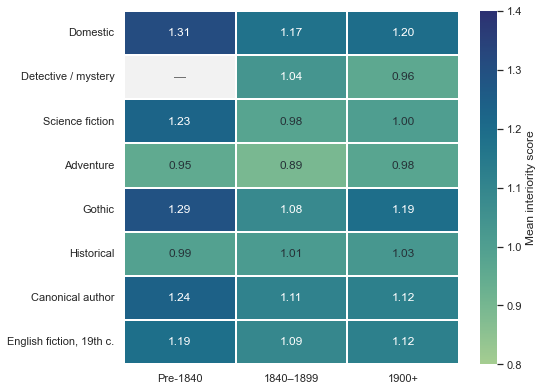

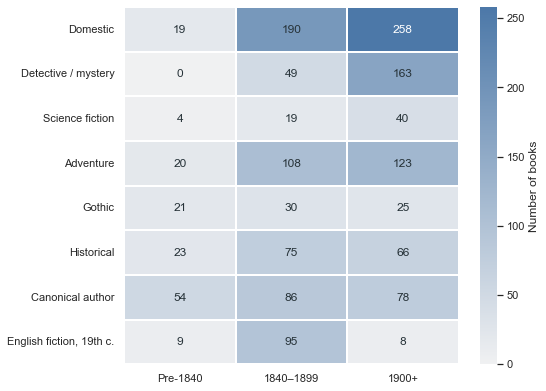

In [4]:
indicator_label_order = [
    LINE_LABELS[column] for column in LINE_GROUP_COLUMNS
]

indicator_count_matrix = (
    indicator_time_summary.pivot(
        index="group_label",
        columns="time_period",
        values="books",
    )
    .reindex(
        index=indicator_label_order,
        columns=TIME_PERIOD_ORDER,
    )
)
indicator_score_matrix = (
    indicator_time_summary.pivot(
        index="group_label",
        columns="time_period",
        values="average_interiority",
    )
    .reindex(
        index=indicator_label_order,
        columns=TIME_PERIOD_ORDER,
    )
)

indicator_count_display = indicator_count_matrix.fillna(0)
indicator_count_vmin = 0
indicator_count_vmax = np.nanmax(indicator_count_matrix.to_numpy())
indicator_score_annotations = indicator_score_matrix.apply(
    lambda column: column.map(
        lambda value: "—" if pd.isna(value) else f"{value:.2f}"
    )
)
period_tick_labels = ["Pre-1840", "1840–1899", "1900+"]

score_vmin = 0.8
score_vmax = 1.4
score_cmap = sns.color_palette("crest", as_cmap=True)

fig, ax = plt.subplots(figsize=(7.6, 5.4))
sns.heatmap(
    indicator_score_matrix,
    annot=False,
    cmap=score_cmap,
    vmin=score_vmin,
    vmax=score_vmax,
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Mean interiority score"},
    ax=ax,
)
ax.set_facecolor("#F2F2F2")
for row_index in range(indicator_score_matrix.shape[0]):
    for column_index in range(indicator_score_matrix.shape[1]):
        value = indicator_score_matrix.iloc[row_index, column_index]
        if pd.isna(value):
            label = "—"
            text_color = "#555555"
        else:
            label = f"{value:.2f}"
            normalized_value = np.clip(
                (value - score_vmin) / (score_vmax - score_vmin),
                0,
                1,
            )
            red, green, blue, _ = score_cmap(normalized_value)
            luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
            text_color = "white" if luminance < 0.52 else "#263238"
        ax.text(
            column_index + 0.5,
            row_index + 0.5,
            label,
            ha="center",
            va="center",
            color=text_color,
        )
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_xticklabels(period_tick_labels, rotation=0)
plt.tight_layout(pad=0.5)
figure_2_table_dir = ROOT / "analysis" / "outputs" / "descriptive" / "tables"
figure_2_table_dir.mkdir(parents=True, exist_ok=True)
indicator_time_summary.to_csv(
    figure_2_table_dir / "figure_2_indicator_group_period_summary.csv",
    index=False,
)
save_figure(
    fig,
    ROOT / "analysis" / "figures",
    "figure_2_indicator_group_heatmaps",
)
plt.show()

count_cmap = sns.light_palette("#4C78A8", as_cmap=True)
count_fig, count_ax = plt.subplots(figsize=(7.6, 5.4))
sns.heatmap(
    indicator_count_display,
    annot=False,
    cmap=count_cmap,
    vmin=indicator_count_vmin,
    vmax=indicator_count_vmax,
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "Number of books"},
    ax=count_ax,
)
for row_index in range(indicator_count_display.shape[0]):
    for column_index in range(indicator_count_display.shape[1]):
        value = indicator_count_display.iloc[row_index, column_index]
        normalized_value = np.clip(
            (value - indicator_count_vmin)
            / (indicator_count_vmax - indicator_count_vmin),
            0,
            1,
        )
        red, green, blue, _ = count_cmap(normalized_value)
        luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
        count_ax.text(
            column_index + 0.5,
            row_index + 0.5,
            f"{value:.0f}",
            ha="center",
            va="center",
            color="white" if luminance < 0.52 else "#263238",
        )
count_ax.set_xlabel("")
count_ax.set_ylabel("")
count_ax.set_xticklabels(period_tick_labels, rotation=0)
plt.tight_layout(pad=0.5)
save_figure(
    count_fig,
    ROOT / "analysis" / "figures",
    "appendix_figure_2_book_counts",
)
plt.show()


## Paper Figure 7 - Publication-Year Trend

Points represent four mutually exclusive book groups; trend lines combine the two domestic groups and the two non-domestic groups. Trends use centered 20-year windows beginning at 1800 and evaluated every five years; ribbons indicate 95% book-level bootstrap confidence intervals. Windows without books are omitted.


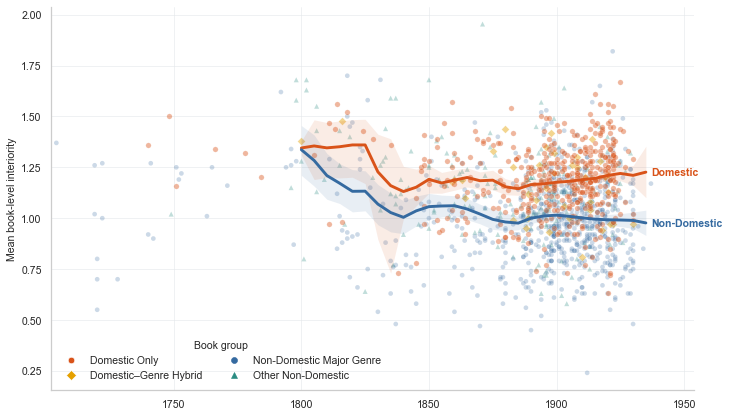

The figure contains **1,348 books** across the full available publication-year range, one point per book. Another **0 books** cannot be plotted because their score is missing. Among plotted books, **0** have no `broad_group`. Trend uncertainty is calculated by resampling books within each rolling window, not passages.

In [3]:
from matplotlib.lines import Line2D

plot_data = book_summary_analysis.dropna(
    subset=["publication_year", "avg_interiority_score"]
).copy()
plot_data["publication_year_plot"] = pd.to_numeric(
    plot_data["publication_year"], errors="coerce"
)
plot_data["average_interiority_score"] = pd.to_numeric(
    plot_data["avg_interiority_score"], errors="coerce"
)
plot_data["broad_group_plot"] = plot_data["broad_group"].fillna("missing")
plot_data["domestic_status"] = np.select(
    [
        plot_data["broad_group_plot"].isin(
            ["domestic_only", "domestic_and_genre"]
        ),
        plot_data["broad_group_plot"].isin(
            [
                "major_genre_non_domestic",
                "other_non_domestic_non_major_genre",
            ]
        ),
    ],
    ["Domestic", "Non-domestic"],
    default=None,
)

SECTION4_TREND_START_YEAR = 1800
scatter_plot_data = plot_data.copy()

# Section-specific palette: related families preserve the domestic versus
# non-domestic distinction, while hue and marker shape distinguish subgroups.
SECTION4_BROAD_GROUP_COLORS = {
    "domestic_only": "#D95319",  # strong orange-red
    "domestic_and_genre": "#E5A000",  # golden orange
    "major_genre_non_domestic": "#356AA0",  # medium blue
    "other_non_domestic_non_major_genre": "#2A8C82",  # teal
    "missing": "#D9DDE1",
}
SECTION4_BROAD_GROUP_LABELS = {
    "domestic_only": "Domestic Only",
    "domestic_and_genre": "Domestic–Genre Hybrid",
    "major_genre_non_domestic": "Non-Domestic Major Genre",
    "other_non_domestic_non_major_genre": "Other Non-Domestic",
}
BROAD_TREND_COLORS = {
    "Domestic": SECTION4_BROAD_GROUP_COLORS["domestic_only"],
    "Non-domestic": SECTION4_BROAD_GROUP_COLORS[
        "major_genre_non_domestic"
    ],
}
broad_group_rolling_trends = rolling_book_bootstrap(
    plot_data.dropna(subset=["domestic_status"]),
    group_column="domestic_status",
    groups=["Domestic", "Non-domestic"],
    year_column="publication_year_plot",
    score_column="average_interiority_score",
    window_years=20,
    evaluation_step=5,
    minimum_books=1,
    seed_key="broad_group_domestic_status_trend",
)
broad_group_rolling_trends = broad_group_rolling_trends.loc[
    broad_group_rolling_trends["evaluation_year"].ge(
        SECTION4_TREND_START_YEAR
    )
].copy()

scatter_output_dir = ROOT / "analysis" / "figures"
scatter_table_dir = ROOT / "analysis" / "outputs" / "descriptive" / "tables"
scatter_output_dir.mkdir(parents=True, exist_ok=True)
scatter_table_dir.mkdir(parents=True, exist_ok=True)
broad_group_rolling_trends.to_csv(
    scatter_table_dir / "broad_group_domestic_non_domestic_rolling_trends.csv",
    index=False,
)

scatter_draw_order = [
    "missing",
    "other_non_domestic_non_major_genre",
    "major_genre_non_domestic",
    "domestic_and_genre",
    "domestic_only",
]
scatter_style = {
    "domestic_only": {"size": 29, "alpha": 0.42, "zorder": 4},
    "domestic_and_genre": {"size": 30, "alpha": 0.44, "zorder": 4},
    "major_genre_non_domestic": {"size": 22, "alpha": 0.25, "zorder": 2},
    "other_non_domestic_non_major_genre": {"size": 25, "alpha": 0.29, "zorder": 2},
    "missing": {"size": 18, "alpha": 0.14, "zorder": 1},
}

figure_text_size = 10.5
fig, ax = plt.subplots(figsize=(10.2, 5.8))
present_groups = set(scatter_plot_data["broad_group_plot"])
for group in scatter_draw_order:
    if group not in present_groups:
        continue
    group_data = scatter_plot_data.loc[
        scatter_plot_data["broad_group_plot"].eq(group)
    ]
    style = scatter_style[group]
    ax.scatter(
        group_data["publication_year_plot"],
        group_data["average_interiority_score"],
        s=style["size"],
        alpha=style["alpha"],
        marker=BROAD_GROUP_MARKERS[group],
        color=SECTION4_BROAD_GROUP_COLORS[group],
        edgecolors="white" if group.startswith("domestic") else "none",
        linewidths=0.35 if group.startswith("domestic") else 0,
        zorder=style["zorder"],
    )

for trend_group in ["Domestic", "Non-domestic"]:
    trend = broad_group_rolling_trends.loc[
        broad_group_rolling_trends["domestic_status"].eq(trend_group)
    ].sort_values("evaluation_year")
    x = trend["evaluation_year"].to_numpy(float)
    estimate = trend["estimate"].to_numpy(float)
    ci_low = trend["ci_low"].to_numpy(float)
    ci_high = trend["ci_high"].to_numpy(float)
    valid_ci = np.isfinite(ci_low) & np.isfinite(ci_high)
    color = BROAD_TREND_COLORS[trend_group]
    ax.fill_between(
        x,
        ci_low,
        ci_high,
        where=valid_ci,
        color=color,
        alpha=0.11,
        linewidth=0,
        zorder=5,
    )
    ax.plot(
        x,
        estimate,
        color=color,
        linewidth=2.9,
        zorder=6,
    )
    valid_trend = trend.dropna(subset=["estimate"])
    if len(valid_trend):
        last = valid_trend.iloc[-1]
        ax.text(
            last["evaluation_year"] + 2.0,
            last["estimate"],
            {"Domestic": "Domestic", "Non-domestic": "Non-Domestic"}[trend_group],
            color=color,
            fontsize=figure_text_size,
            fontweight="bold",
            va="center",
        )

legend_groups = [group for group in BROAD_GROUP_ORDER if group in present_groups]
legend_handles = [
    Line2D(
        [0],
        [0],
        marker=BROAD_GROUP_MARKERS[group],
        linestyle="none",
        markersize=6.5 if group.startswith("domestic") else 6,
        markerfacecolor=SECTION4_BROAD_GROUP_COLORS[group],
        markeredgecolor=(
            "white"
            if group.startswith("domestic")
            else SECTION4_BROAD_GROUP_COLORS[group]
        ),
        markeredgewidth=0.6,
        label=SECTION4_BROAD_GROUP_LABELS[group],
    )
    for group in legend_groups
]
ax.legend(
    handles=legend_handles,
    title="Book group",
    frameon=False,
    loc="lower left",
    ncol=2,
    fontsize=figure_text_size,
    title_fontsize=figure_text_size,
)
ax.set_xlabel("")
ax.set_ylabel("Mean book-level interiority", fontsize=figure_text_size)
ax.tick_params(axis="both", labelsize=figure_text_size)
ax.set_xlim(
    scatter_plot_data["publication_year_plot"].min() - 2,
    scatter_plot_data["publication_year_plot"].max() + 15,
)
ax.grid(axis="both", color="#E4E7EA", linewidth=0.7, alpha=0.8)
sns.despine(ax=ax)
plt.tight_layout(pad=0.6)
save_figure(fig, scatter_output_dir, "figure_7_publication_year_broad_group_scatter")
plt.show()

missing_score = int(book_summary_analysis["avg_interiority_score"].isna().sum())
missing_group_plotted = int(
    scatter_plot_data["broad_group"].isna().sum()
)
display(
    Markdown(
        f"The figure contains **{len(scatter_plot_data):,} books** across the full available publication-year range, "
        "one point per book. "
        f"Another **{missing_score:,} books** cannot be plotted because their score is missing. "
        f"Among plotted books, **{missing_group_plotted:,}** have no `broad_group`. "
        "Trend uncertainty is calculated by resampling books within each rolling window, not passages."
    )
)


## Supporting descriptive analyses

The following retained summaries and figures are useful corpus checks, robustness views, or exploratory descriptions; they are not numbered manuscript figures.


### Interiority time series by book classification

The plotting workflow below is reusable across time columns. For each indicator, it keeps books where the indicator equals `1`, drops rows with missing indicator, time, or average interiority score, and never imputes missing values.


In [40]:
LINE_GROUP_COLUMNS = [
    "is_domestic",
    "is_detective_mystery",
    "is_science_fiction",
    "is_adventure",
    "is_gothic",
    "is_historical",
    "is_canonical_author",
    "is_english_fiction_19c",
]

LINE_LABELS = {
    "is_domestic": "Domestic",
    "is_detective_mystery": "Detective / mystery",
    "is_science_fiction": "Science fiction",
    "is_adventure": "Adventure",
    "is_gothic": "Gothic",
    "is_historical": "Historical",
    "is_canonical_author": "Canonical author",
    "is_english_fiction_19c": "English fiction, 19th c.",
}

LINE_COLORS = dict(
    zip(
        LINE_GROUP_COLUMNS,
        sns.color_palette("tab10", n_colors=len(LINE_GROUP_COLUMNS)),
    )
)

In [41]:
def add_year_period_column(
    data,
    width,
    year_column="publication_year",
    output_column=None,
):
    """Return a copy with an ordered year-period column such as 1700-1724."""
    if width <= 0:
        raise ValueError("width must be a positive integer")
    if year_column not in data.columns:
        raise KeyError(f"Time source column not found: {year_column}")

    output_column = output_column or f"period_{width}yr"
    result = data.copy()
    years = pd.to_numeric(result[year_column], errors="coerce")
    valid = years.notna()

    period_labels = pd.Series(pd.NA, index=result.index, dtype="string")
    starts = (years.loc[valid].astype(int) // width) * width
    period_labels.loc[valid] = (
        starts.astype(str) + "-" + (starts + width - 1).astype(str)
    )

    if valid.any():
        first_start = int(starts.min())
        last_start = int(starts.max())
        ordered_labels = [
            f"{start}-{start + width - 1}"
            for start in range(first_start, last_start + width, width)
        ]
    else:
        ordered_labels = []

    result[output_column] = pd.Categorical(
        period_labels,
        categories=ordered_labels,
        ordered=True,
    )
    return result


book_summary_analysis = add_year_period_column(
    book_summary_analysis,
    width=25,
    output_column="period_25yr",
)
book_summary_analysis = add_year_period_column(
    book_summary_analysis,
    width=50,
    output_column="period_50yr",
)

display(
    book_summary_analysis[
        ["publication_year", "period_25yr", "period_50yr"]
    ].drop_duplicates().sort_values("publication_year").head(12)
)

,publication_year,period_25yr,period_50yr
25,1704,1700-1724,1700-1749
6,1719,1700-1724,1700-1749
182,1720,1700-1724,1700-1749
5,1722,1700-1724,1700-1749
283,1728,1725-1749,1700-1749
20,1740,1725-1749,1700-1749
69,1741,1725-1749,1700-1749
233,1742,1725-1749,1700-1749
24,1748,1725-1749,1700-1749
21,1749,1725-1749,1700-1749


In [42]:
def plot_indicator_timeseries(
    data,
    time_column,
    group_columns=LINE_GROUP_COLUMNS,
    score_column="avg_interiority_score",
    title=None,
    xlabel=None,
    figsize=(12, 7),
):
    """Plot one equal-book mean line per binary indicator for any time column."""
    required = ["gutenberg_id", time_column, score_column, *group_columns]
    missing = [column for column in required if column not in data.columns]
    if missing:
        raise KeyError(f"Required columns not found: {missing}")

    line_frames = []
    coverage_rows = []

    for group_column in group_columns:
        group_books = (
            data[
                [
                    "gutenberg_id",
                    time_column,
                    score_column,
                    group_column,
                ]
            ]
            .dropna(subset=[time_column, score_column, group_column])
            .loc[lambda frame: frame[group_column].eq(1)]
            .copy()
        )

        grouped = (
            group_books.groupby(time_column, observed=True, as_index=False)
            .agg(
                avg_interiority_score=(score_column, "mean"),
                books_in_period=("gutenberg_id", "nunique"),
            )
        )
        grouped["group_column"] = group_column
        line_frames.append(grouped)

        coverage_rows.append(
            {
                "group_column": group_column,
                "books": group_books["gutenberg_id"].nunique(),
                "time_values": grouped[time_column].nunique(),
                "first_time_value": (
                    grouped[time_column].min() if len(grouped) else pd.NA
                ),
                "last_time_value": (
                    grouped[time_column].max() if len(grouped) else pd.NA
                ),
            }
        )

    line_data = pd.concat(line_frames, ignore_index=True)
    coverage = pd.DataFrame(coverage_rows)

    is_categorical = isinstance(data[time_column].dtype, pd.CategoricalDtype)
    if is_categorical:
        observed_values = set(line_data[time_column].dropna())
        time_order = [
            value
            for value in data[time_column].cat.categories
            if value in observed_values
        ]
        time_positions = {
            value: position for position, value in enumerate(time_order)
        }

    fig, ax = plt.subplots(figsize=figsize)
    for group_column in group_columns:
        series = line_data.loc[
            line_data["group_column"].eq(group_column)
        ].copy()

        if is_categorical:
            series["_plot_x"] = series[time_column].map(time_positions).astype(float)
            series = series.sort_values("_plot_x")
            x_values = series["_plot_x"]
            marker = "o"
        else:
            series = series.sort_values(time_column)
            x_values = series[time_column]
            marker = None

        ax.plot(
            x_values,
            series["avg_interiority_score"],
            color=LINE_COLORS.get(group_column),
            linewidth=1.8,
            marker=marker,
            markersize=4.5,
            alpha=0.88,
            label=LINE_LABELS.get(group_column, group_column),
        )

    if is_categorical:
        ax.set_xticks(range(len(time_order)), time_order, rotation=45, ha="right")

    ax.set_xlabel(xlabel or time_column)
    ax.set_ylabel("Average interiority score")
    ax.set_title(title or f"Average interiority by {time_column}")
    ax.legend(
        title="Books with indicator = 1",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    sns.despine(ax=ax)
    plt.tight_layout()
    plt.show()

    display(Markdown(f"**Coverage for `{time_column}` after dropping NA**"))
    display(coverage)
    return line_data, coverage, ax

#### Annual series

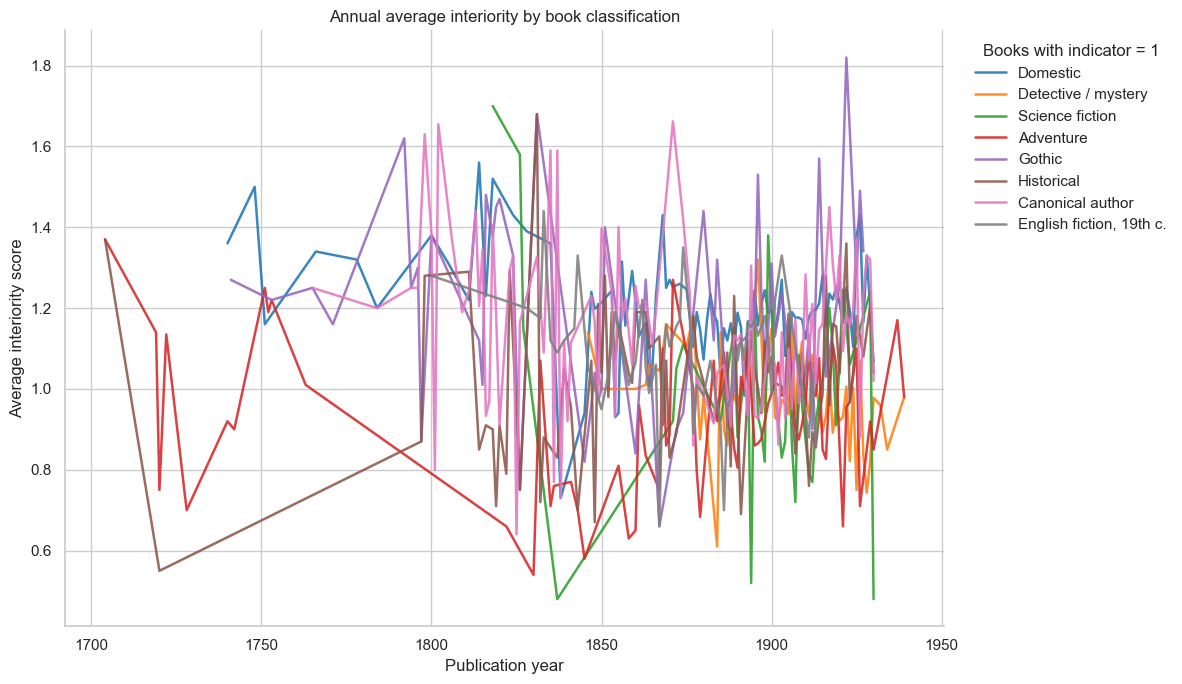

**Coverage for `publication_year` after dropping NA**

,group_column,books,time_values,first_time_value,last_time_value
0,is_domestic,467,92,1740,1930
1,is_detective_mystery,212,59,1846,1939
2,is_science_fiction,63,38,1818,1930
3,is_adventure,251,79,1704,1939
4,is_gothic,76,58,1741,1927
5,is_historical,164,82,1704,1930
6,is_canonical_author,218,96,1765,1930
7,is_english_fiction_19c,112,52,1800,1913


In [43]:
annual_line_data, annual_line_coverage, annual_line_ax = (
    plot_indicator_timeseries(
        book_summary_analysis,
        time_column="publication_year",
        title="Annual average interiority by book classification",
        xlabel="Publication year",
    )
)

#### 25-year series

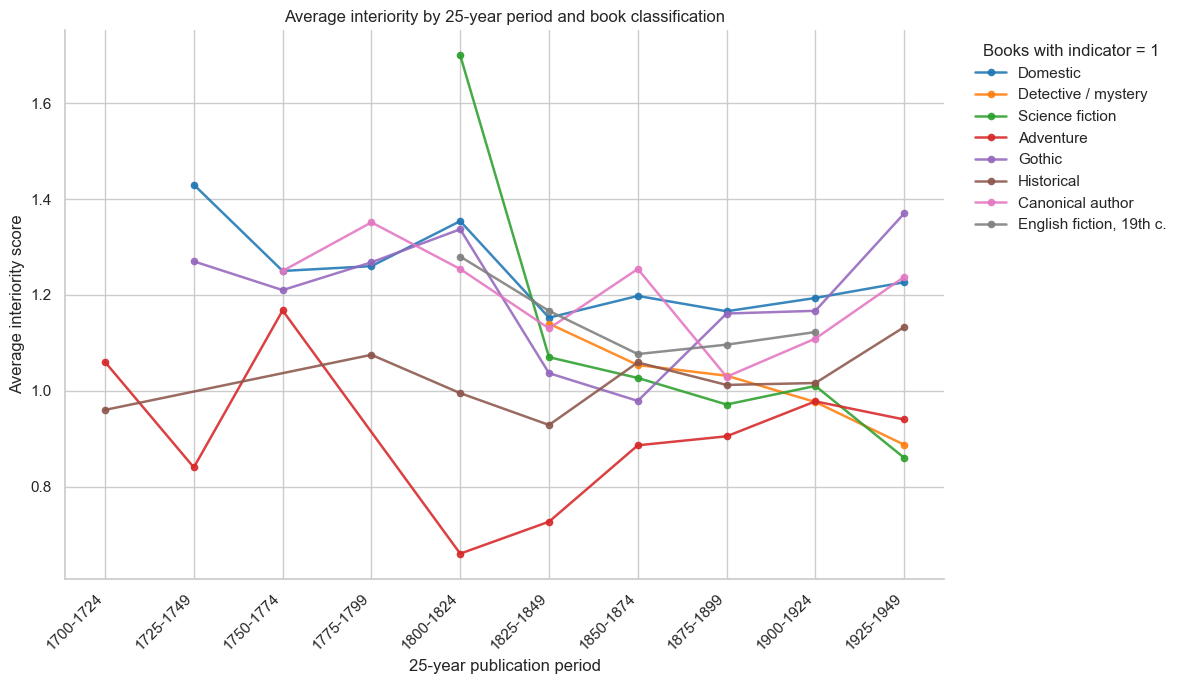

**Coverage for `period_25yr` after dropping NA**

,group_column,books,time_values,first_time_value,last_time_value
0,is_domestic,467,9,1725-1749,1925-1949
1,is_detective_mystery,212,5,1825-1849,1925-1949
2,is_science_fiction,63,6,1800-1824,1925-1949
3,is_adventure,251,9,1700-1724,1925-1949
4,is_gothic,76,9,1725-1749,1925-1949
5,is_historical,164,8,1700-1724,1925-1949
6,is_canonical_author,218,8,1750-1774,1925-1949
7,is_english_fiction_19c,112,5,1800-1824,1900-1924


In [44]:
period_25yr_line_data, period_25yr_coverage, period_25yr_ax = (
    plot_indicator_timeseries(
        book_summary_analysis,
        time_column="period_25yr",
        title="Average interiority by 25-year period and book classification",
        xlabel="25-year publication period",
    )
)

#### 50-year series

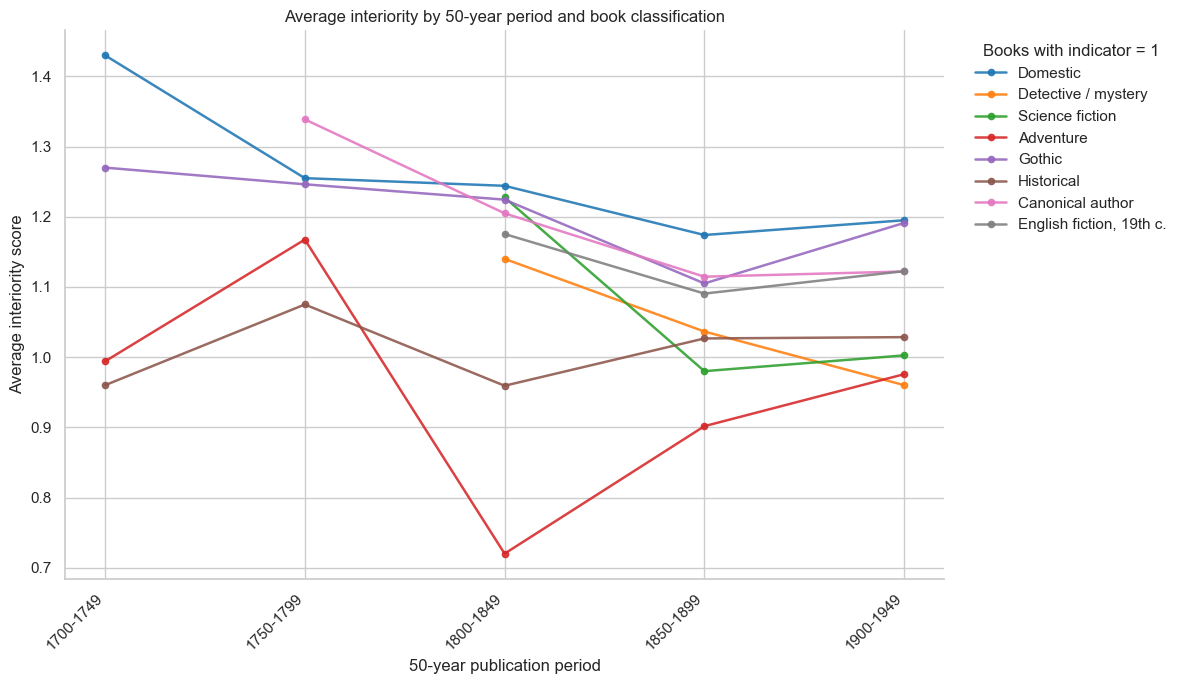

**Coverage for `period_50yr` after dropping NA**

,group_column,books,time_values,first_time_value,last_time_value
0,is_domestic,467,5,1700-1749,1900-1949
1,is_detective_mystery,212,3,1800-1849,1900-1949
2,is_science_fiction,63,3,1800-1849,1900-1949
3,is_adventure,251,5,1700-1749,1900-1949
4,is_gothic,76,5,1700-1749,1900-1949
5,is_historical,164,5,1700-1749,1900-1949
6,is_canonical_author,218,4,1750-1799,1900-1949
7,is_english_fiction_19c,112,3,1800-1849,1900-1949


In [45]:
period_50yr_line_data, period_50yr_coverage, period_50yr_ax = (
    plot_indicator_timeseries(
        book_summary_analysis,
        time_column="period_50yr",
        title="Average interiority by 50-year period and book classification",
        xlabel="50-year publication period",
    )
)

All three charts use the same function. To use another time variable later, create or select that column and pass its name through `time_column`. No missing values are imputed.

### Distribution across three historical periods

The finalized `time_period` values are `<1840`, `1840-1899`, and `1900+`. Counts include every book in the relevant group; average interiority uses only books with non-missing `avg_interiority_score`.


In [46]:
time_period_summary = (
    book_summary_analysis.groupby(
        "time_period",
        observed=True,
        as_index=False,
    )
    .agg(
        books=("gutenberg_id", "nunique"),
        books_with_score=("avg_interiority_score", "count"),
        average_interiority=("avg_interiority_score", "mean"),
        median_interiority=("avg_interiority_score", "median"),
        std_interiority=("avg_interiority_score", "std"),
        minimum_interiority=("avg_interiority_score", "min"),
        maximum_interiority=("avg_interiority_score", "max"),
    )
)

display(
    time_period_summary.style.format(
        {
            "average_interiority": "{:.3f}",
            "median_interiority": "{:.3f}",
            "std_interiority": "{:.3f}",
            "minimum_interiority": "{:.3f}",
            "maximum_interiority": "{:.3f}",
        }
    )
)


,time_period,books,books_with_score,average_interiority,median_interiority,std_interiority,minimum_interiority,maximum_interiority
0,<1840,109,109,1.160,1.200,0.296,0.480,1.700
1,1840-1899,556,556,1.067,1.070,0.211,0.450,1.954
2,1900+,683,683,1.072,1.070,0.211,0.240,1.820


#### Distribution by `broad_group_analysis`


In [48]:
broad_group_analysis_for_summary = book_summary_analysis.assign(
    
    
    
    _plot=book_summary_analysis["broad_group_analysis"].fillna("missing")
)

broad_group_analysis_time_summary = (
    broad_group_analysis_for_summary.groupby(
        ["time_period", "broad_group_analysis"],
        observed=True,
        as_index=False,
    )
    .agg(
        books=("gutenberg_id", "nunique"),
        books_with_score=("avg_interiority_score", "count"),
        average_interiority=("avg_interiority_score", "mean"),
    )
)
broad_group_analysis_time_summary["share_within_time_period"] = (
    broad_group_analysis_time_summary["books"]
    / broad_group_analysis_time_summary.groupby("time_period", observed=True)["books"].transform("sum")
)

display(
    broad_group_analysis_time_summary.style.format(
        {
            "average_interiority": "{:.3f}",
            "share_within_time_period": "{:.1%}",
        }
    )
)


,time_period,broad_group_analysis,books,books_with_score,average_interiority,share_within_time_period
0,<1840,all_domestic,19,19,1.311,17.4%
1,<1840,major_genre_non_domestic,59,59,1.062,54.1%
2,<1840,other_non_domestic_non_major_genre,31,31,1.255,28.4%
3,1840-1899,all_domestic,190,190,1.173,34.2%
4,1840-1899,major_genre_non_domestic,253,253,0.964,45.5%
5,1840-1899,other_non_domestic_non_major_genre,113,113,1.119,20.3%
6,1900+,all_domestic,258,258,1.195,37.8%
7,1900+,major_genre_non_domestic,370,370,0.985,54.2%
8,1900+,other_non_domestic_non_major_genre,55,55,1.089,8.1%


In [49]:
broad_group_analysis_order = [
    group
    for group in [
        "all_domestic",
        "major_genre_non_domestic",
        "other_non_domestic_non_major_genre",
        "missing",
    ]
    if group in set(broad_group_analysis_time_summary["broad_group_analysis"])
]

broad_count_matrix = (
    broad_group_analysis_time_summary.pivot(
        index="time_period",
        columns="broad_group_analysis_plot",
        values="books",
    )
    .reindex(index=TIME_PERIOD_ORDER, columns=broad_group_analysis_order)
    .fillna(0)
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
broad_count_matrix.plot(
    kind="bar",
    stacked=True,
    color=[
        BROAD_GROUP_ANALYSIS_COLORS.get(group, "#6C757D")
        for group in broad_group_analysis_order
    ],
    ax=axes[0],
)
axes[0].set_title("Book counts by period and broad-group analysis")
axes[0].set_xlabel("Time period")
axes[0].set_ylabel("Number of books")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Broad-group analysis", frameon=False, fontsize=8)

sns.barplot(
    data=broad_group_analysis_time_summary,
    x="time_period",
    y="average_interiority",
    hue="broad_group_analysis_plot",
    order=TIME_PERIOD_ORDER,
    hue_order=broad_group_analysis_order,
    palette={
        group: BROAD_GROUP_ANALYSIS_COLORS.get(group, "#6C757D")
        for group in broad_group_analysis_order
    },
    errorbar=None,
    ax=axes[1],
)
axes[1].set_title("Average interiority by period and broad-group analysis")
axes[1].set_xlabel("Time period")
axes[1].set_ylabel("Average interiority score")
axes[1].legend(title="Broad-group analysis", frameon=False, fontsize=8)

for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()


KeyError: 'broad_group_analysis_plot'

#### Indicator-group distribution table


The `broad_group` categories are mutually exclusive, while the eight Figure 2 indicator groups overlap. Consequently, indicator-group counts should not be summed to obtain the number of unique books in a period.


### Quotation metrics


In [50]:
df_quote = book_summary_analysis.copy()

count_cols = [
    "n_narration_only",
    "n_narration_dominant",
    "n_quotation_dominant",
    "n_quotation_only"
]

metric_cols = [
    "overall_quote_share",
    "narration_quotation_interiority_gap",
    "narration_quotation_high_rate_gap",
    "high_narration_enrichment"
]

for col in count_cols + metric_cols:
    df_quote[col] = pd.to_numeric(df_quote[col], errors="coerce")

# Whether a book has enough passages on both sides
df_quote["gap_eligible"] = (
    df_quote["n_narration_dominant"].ge(10)
    & df_quote["n_quotation_dominant"].ge(10)
)

df_quote["min_dominant_n"] = df_quote[
    ["n_narration_dominant", "n_quotation_dominant"]
].min(axis=1)

print(f"Total books: {len(df_quote):,}")
print(
    f"Books eligible for gap metrics: "
    f"{df_quote['gap_eligible'].sum():,} "
    f"({df_quote['gap_eligible'].mean():.1%})"
)

Total books: 1,348
Books eligible for gap metrics: 1,250 (92.7%)


In [51]:
distribution_summary = (
    df_quote[metric_cols + count_cols]
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
    .T
)

distribution_summary["missing_n"] = (
    df_quote[metric_cols + count_cols].isna().sum()
)

distribution_summary["missing_pct"] = (
    df_quote[metric_cols + count_cols].isna().mean()
)

display(distribution_summary.round(3))

,count,mean,std,min,5%,25%,50%,75%,95%,max,missing_n,missing_pct
overall_quote_share,1348.0,0.417,0.140,0.000,0.164,0.336,0.425,0.508,0.636,0.844,0,0.000
narration_quotation_interiority_gap,1250.0,0.130,0.266,-0.674,-0.320,-0.045,0.125,0.309,0.565,1.135,98,0.073
narration_quotation_high_rate_gap,1250.0,0.145,0.172,-0.359,-0.120,0.029,0.134,0.258,0.439,0.692,98,0.073
high_narration_enrichment,1348.0,0.086,0.112,-0.414,-0.105,0.019,0.090,0.157,0.262,0.445,0,0.000
n_narration_only,1348.0,33.217,16.228,2.000,13.000,22.000,31.000,40.250,63.000,100.000,0,0.000
n_narration_dominant,1348.0,45.586,16.705,4.000,22.000,35.000,44.000,54.000,77.000,100.000,0,0.000
n_quotation_dominant,1348.0,30.302,14.190,0.000,7.350,20.000,30.000,39.000,55.000,83.000,0,0.000
n_quotation_only,1348.0,7.966,7.816,0.000,0.000,3.000,6.000,11.000,23.000,72.000,0,0.000


Across the corpus, interiority is more often concentrated in narration-dominant than quotation-dominant passages. This pattern is especially consistent for the probability of receiving a HIGH interiority label, although substantial variation remains across individual books.

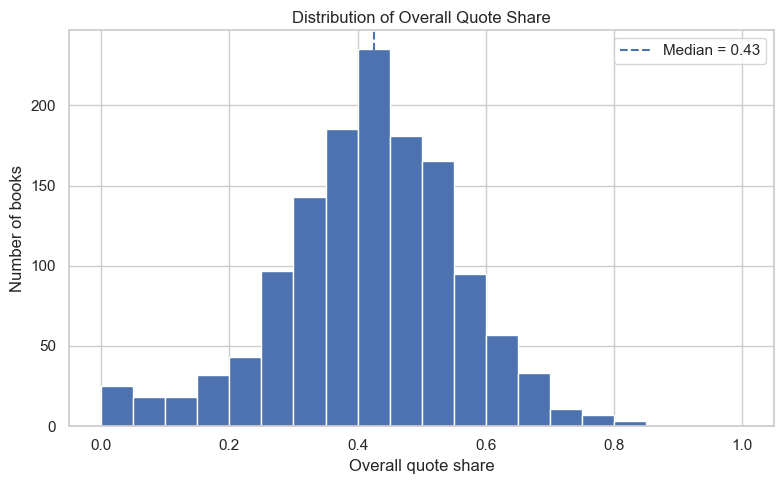

In [52]:
quote_share_summary = pd.Series({
    "n_books": df_quote["overall_quote_share"].notna().sum(),
    "mean": df_quote["overall_quote_share"].mean(),
    "median": df_quote["overall_quote_share"].median(),
    "purely_nonquoted_pct": (
        df_quote["overall_quote_share"].eq(0).mean()
    ),
    "below_10pct_quote": (
        df_quote["overall_quote_share"].lt(0.10).mean()
    ),
    "above_50pct_quote": (
        df_quote["overall_quote_share"].gt(0.50).mean()
    ),
    "above_75pct_quote": (
        df_quote["overall_quote_share"].gt(0.75).mean()
    )
})

plt.figure(figsize=(8, 5))

plt.hist(
    df_quote["overall_quote_share"].dropna(),
    bins=np.linspace(0, 1, 21),
    edgecolor="white"
)

plt.axvline(
    df_quote["overall_quote_share"].median(),
    linestyle="--",
    label=f"Median = {df_quote['overall_quote_share'].median():.2f}"
)

plt.xlabel("Overall quote share")
plt.ylabel("Number of books")
plt.title("Distribution of Overall Quote Share")
plt.legend()

plt.tight_layout()
plt.show()

In [53]:
gap_metrics = [
    "narration_quotation_interiority_gap",
    "narration_quotation_high_rate_gap",
    "high_narration_enrichment"
]

near_zero_threshold = 0.05

sign_rows = []

for metric in gap_metrics:
    values = df_quote[metric].dropna()

    sign_rows.append({
        "metric": metric,
        "n_books": len(values),
        "mean": values.mean(),
        "median": values.median(),
        "positive_pct": (values > near_zero_threshold).mean(),
        "near_zero_pct": (
            values.abs() <= near_zero_threshold
        ).mean(),
        "negative_pct": (values < -near_zero_threshold).mean()
    })

sign_summary = pd.DataFrame(sign_rows)

display(sign_summary.round(3))

,metric,n_books,mean,median,positive_pct,near_zero_pct,negative_pct
0,narration_quotation_interiority_gap,1250,0.130,0.125,0.633,0.123,0.244
1,narration_quotation_high_rate_gap,1250,0.145,0.134,0.695,0.184,0.121
2,high_narration_enrichment,1348,0.086,0.090,0.657,0.249,0.094


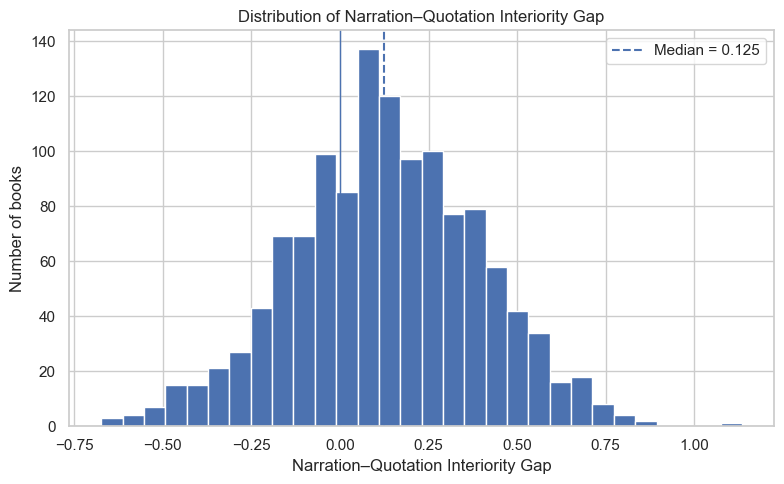

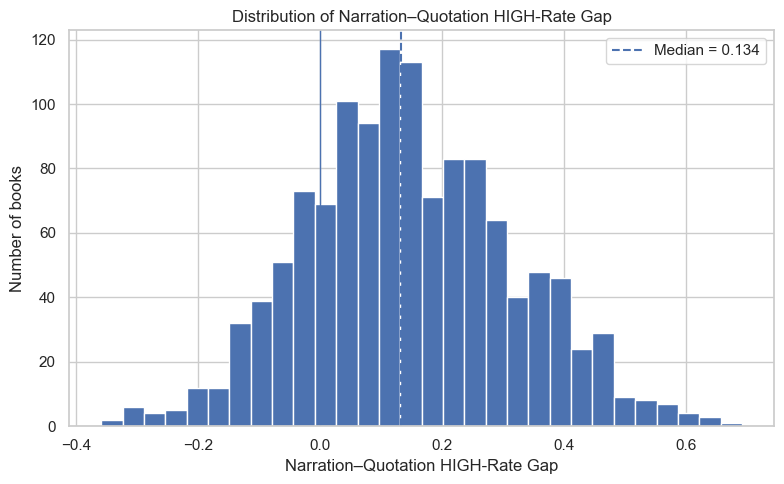

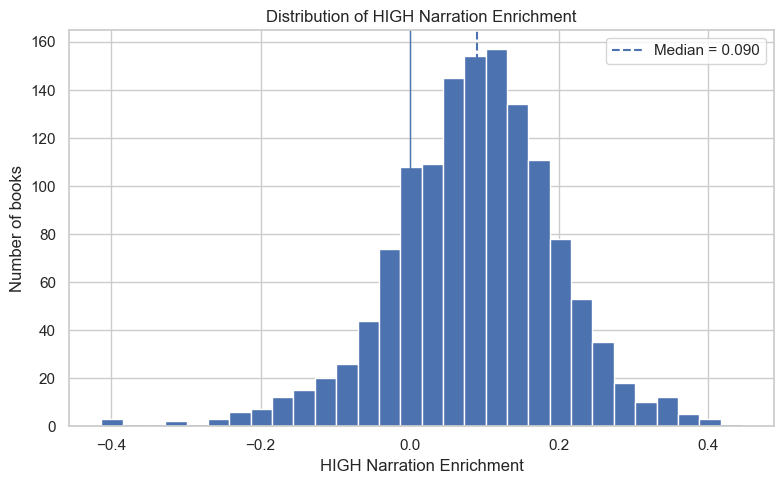

In [54]:
metric_titles = {
    "narration_quotation_interiority_gap":
        "Narration–Quotation Interiority Gap",

    "narration_quotation_high_rate_gap":
        "Narration–Quotation HIGH-Rate Gap",

    "high_narration_enrichment":
        "HIGH Narration Enrichment"
}

for metric in gap_metrics:
    values = df_quote[metric].dropna()

    plt.figure(figsize=(8, 5))

    plt.hist(
        values,
        bins=30,
        edgecolor="white"
    )

    plt.axvline(0, linewidth=1)
    plt.axvline(
        values.median(),
        linestyle="--",
        label=f"Median = {values.median():.3f}"
    )

    plt.xlabel(metric_titles[metric])
    plt.ylabel("Number of books")
    plt.title(f"Distribution of {metric_titles[metric]}")
    plt.legend()

    plt.tight_layout()
    plt.show()

In [55]:
id_candidates = [
    "gutenberg_id",
    "book",
    "title",
    "author_display",
    "published_year",
    "category",
    "narrative_mode"
]

id_cols = [
    col for col in id_candidates
    if col in df_quote.columns
]

for metric in gap_metrics:
    display_cols = (
        id_cols
        + [
            "overall_quote_share",
            "n_narration_dominant",
            "n_quotation_dominant",
            metric
        ]
    )

    print(f"\nHighest values: {metric}")
    display(
        df_quote[display_cols]
        .dropna(subset=[metric])
        .nlargest(5, metric)
        .round(3)
    )

    print(f"\nLowest values: {metric}")
    display(
        df_quote[display_cols]
        .dropna(subset=[metric])
        .nsmallest(5, metric)
        .round(3)
    )


Highest values: narration_quotation_interiority_gap


,gutenberg_id,title,author_display,narrative_mode,overall_quote_share,n_narration_dominant,n_quotation_dominant,narration_quotation_interiority_gap
492,40343,Lilian,Arnold Bennett,third_person_candidate,0.310,52,13,1.135
775,2299,Pandora,Henry James,third_person_candidate,0.358,53,29,0.861
316,20157,The Call of the Blood,Robert Hichens,third_person_candidate,0.431,37,25,0.848
1094,47003,Dimbie and I—and Amelia,Mabel Barnes-Grundy,first_person_candidate,0.532,29,38,0.831
810,4397,The Forsyte saga - Complete,John Galsworthy,third_person_candidate,0.257,63,15,0.822



Lowest values: narration_quotation_interiority_gap


,gutenberg_id,title,author_display,narrative_mode,overall_quote_share,n_narration_dominant,n_quotation_dominant,narration_quotation_interiority_gap
1239,69550,"Mercia, the astronomer royal: A romance",A. Garland Mears,third_person_candidate,0.424,48,36,-0.674
743,644,The Haunted Man and the Ghost's Bargain,Charles Dickens,third_person_candidate,0.476,32,31,-0.638
130,3606,"Antonina; Or, The Fall of Rome",Wilkie Collins,third_person_candidate,0.252,71,19,-0.621
687,62304,Black'erchief Dick,Margery Allingham,third_person_candidate,0.356,40,10,-0.600
683,61587,The Old Church Clock,Richard Parkinson,third_person_candidate,0.837,13,82,-0.581



Highest values: narration_quotation_high_rate_gap


,gutenberg_id,title,author_display,narrative_mode,overall_quote_share,n_narration_dominant,n_quotation_dominant,narration_quotation_high_rate_gap
492,40343,Lilian,Arnold Bennett,third_person_candidate,0.310,52,13,0.692
810,4397,The Forsyte saga - Complete,John Galsworthy,third_person_candidate,0.257,63,15,0.651
725,209,The Turn of the Screw,Henry James,first_person_candidate,0.412,41,21,0.640
1254,70659,Beautiful end,Constance Holme,third_person_candidate,0.281,63,21,0.635
350,22000,Kept in the Dark,Anthony Trollope,third_person_candidate,0.471,43,37,0.606


... (2 outputs left out)


Highest values: high_narration_enrichment


,gutenberg_id,title,author_display,narrative_mode,overall_quote_share,n_narration_dominant,n_quotation_dominant,high_narration_enrichment
1183,60096,Mr. Fortune's Practice,H. C. Bailey,third_person_candidate,0.662,16,55,0.445
1133,54239,Mistress Nancy Molesworth: A Tale of Adventure,Joseph Hocking,first_person_candidate,0.521,32,39,0.406
469,38635,Delilah of the Snows,Harold Bindloss,third_person_candidate,0.465,41,38,0.402
643,56841,The Disappearing Eye,Fergus Hume,first_person_candidate,0.617,21,51,0.400
626,55137,The Mystery Queen,Fergus Hume,third_person_candidate,0.522,33,39,0.388



Lowest values: high_narration_enrichment


,gutenberg_id,title,author_display,narrative_mode,overall_quote_share,n_narration_dominant,n_quotation_dominant,high_narration_enrichment
387,26306,Simon,J. Storer Clouston,third_person_candidate,0.579,24,43,-0.414
217,8679,"By England's Aid; Or, the Freeing of the Nethe...",G. A. Henty,third_person_candidate,0.407,52,37,-0.413
1238,69476,Account of an expedition to the interior of Ne...,Mary Fox,third_person_candidate,0.461,51,45,-0.396
344,21556,Travels and Adventures of Monsieur Violet,Frederick Marryat,first_person_candidate,0.173,81,14,-0.375
74,1412,Masterman Ready,Frederick Marryat,third_person_candidate,0.583,33,52,-0.348


#### Author-level narration-quotation interiority gap

Each author's gap is the equal-book mean of the finalized book-level `narration_quotation_interiority_gap`. The ranking is restricted to authors represented by at least five books in the current dataset.


In [62]:
AUTHOR_QUOTE_GAP_METRIC = "narration_quotation_interiority_gap"
MINIMUM_AUTHOR_BOOKS_FOR_QUOTE_RANKING = 5


def representative_author_display(values):
    observed = values.dropna().astype(str)
    if observed.empty:
        return pd.NA
    return observed.mode().iloc[0]


author_quote_gap_summary = (
    df_quote.drop_duplicates("gutenberg_id")
    .dropna(subset=["author_query"])
    .groupby("author_query", as_index=False)
    .agg(
        author_display=(
            "author_display",
            representative_author_display,
        ),
        n_books=("gutenberg_id", "nunique"),
        n_books_with_gap=(AUTHOR_QUOTE_GAP_METRIC, "count"),
        mean_narration_quotation_interiority_gap=(
            AUTHOR_QUOTE_GAP_METRIC,
            "mean",
        ),
    )
)
author_quote_gap_summary["gap_book_coverage"] = (
    author_quote_gap_summary["n_books_with_gap"]
    / author_quote_gap_summary["n_books"]
)
author_quote_gap_summary = author_quote_gap_summary.sort_values(
    [
        "mean_narration_quotation_interiority_gap",
        "n_books_with_gap",
        "author_display",
    ],
    ascending=[True, False, True],
    na_position="last",
).reset_index(drop=True)

author_quote_gap_top10_min5_books = (
    author_quote_gap_summary.loc[
        author_quote_gap_summary["n_books"].ge(
            MINIMUM_AUTHOR_BOOKS_FOR_QUOTE_RANKING
        )
        & author_quote_gap_summary[
            "mean_narration_quotation_interiority_gap"
        ].notna()
    ]
    .head(70)
    .reset_index(drop=True)
)
author_quote_gap_top10_min5_books.insert(
    0,
    "rank",
    range(1, len(author_quote_gap_top10_min5_books) + 1),
)

quote_author_table_dir = (
    ROOT / "analysis" / "outputs" / "descriptive" / "tables"
)
quote_author_table_dir.mkdir(parents=True, exist_ok=True)
author_quote_gap_summary.to_csv(
    quote_author_table_dir
    / "quote_author_narration_quotation_interiority_gap_summary.csv",
    index=False,
)
author_quote_gap_top10_min5_books.to_csv(
    quote_author_table_dir
    / "quote_author_narration_quotation_interiority_gap_top10_min5_books.csv",
    index=False,
)

display(
    author_quote_gap_top10_min5_books[
        [
            "rank",
            "author_display",
            "n_books",
            "n_books_with_gap",
            "gap_book_coverage",
            "mean_narration_quotation_interiority_gap",
        ]
    ].style.format(
        {
            "gap_book_coverage": "{:.1%}",
            "mean_narration_quotation_interiority_gap": "{:.3f}",
        }
    )
)

display(
    Markdown(
        "The five-book threshold is based on each author's total contribution to the current dataset. "
        "`n_books_with_gap` reports how many of those books have a nonmissing finalized gap; "
        "the author mean gives each valid book equal weight."
    )
)


,rank,author_display,n_books,n_books_with_gap,gap_book_coverage,mean_narration_quotation_interiority_gap
0,1,G. A. Henty,10,10,100.0%,-0.370
1,2,William Morris,10,7,70.0%,-0.294
2,3,George Chetwynd Griffith,6,6,100.0%,-0.212
3,4,William Godwin,5,4,80.0%,-0.202
4,5,H. Rider Haggard,9,9,100.0%,-0.144
5,6,Edward Bulwer Lytton,9,8,88.9%,-0.124
6,7,Marjorie Bowen,5,5,100.0%,-0.119
7,8,Charles Reade,9,9,100.0%,-0.113
8,9,Eden Phillpotts,5,4,80.0%,-0.105
9,10,William Henry Giles Kingston,10,10,100.0%,-0.088


The five-book threshold is based on each author's total contribution to the current dataset. `n_books_with_gap` reports how many of those books have a nonmissing finalized gap; the author mean gives each valid book equal weight.

### Additional publication-ready book-level comparisons

These supporting figures use exactly one observation per book. Books are never weighted by passage counts.


In [ ]:
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

PUBLICATION_OUTPUT_DIR = ROOT / "analysis" / "outputs" / "descriptive"
PUBLICATION_FIGURE_DIR = PUBLICATION_OUTPUT_DIR / "figures"
PUBLICATION_TABLE_DIR = PUBLICATION_OUTPUT_DIR / "tables"
PUBLICATION_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
PUBLICATION_TABLE_DIR.mkdir(parents=True, exist_ok=True)

BROAD_GROUP_COLORS_PUBLICATION = BROAD_GROUP_COLORS.copy()

publication_book_data = book_summary_analysis.copy()
if publication_book_data["gutenberg_id"].duplicated().any():
    raise ValueError("Publication figures require exactly one row per book.")

publication_book_data["average_interiority_score"] = pd.to_numeric(
    publication_book_data["avg_interiority_score"], errors="coerce"
)
publication_book_data["publication_period"] = pd.cut(
    pd.to_numeric(publication_book_data["publication_year"], errors="coerce"),
    bins=[float("-inf"), 1840, 1900, float("inf")],
    labels=PUBLICATION_PERIODS,
    right=False,
    ordered=True,
)


publication_inventory = pd.DataFrame(
    {
        "books": [publication_book_data["gutenberg_id"].nunique()],
        "books_with_valid_score": [
            publication_book_data["average_interiority_score"].notna().sum()
        ],
        "bootstrap_repetitions": [BOOTSTRAP_REPETITIONS],
        "bootstrap_seed": [BOOTSTRAP_SEED],
    }
)
display(publication_inventory)


,books,books_with_valid_score,bootstrap_repetitions,bootstrap_seed
0,1351,1351,5000,20260731


#### Corpus composition overview


,broad_group,corpus_books,group_label,corpus_pct
0,major_genre_non_domestic,682,Non-domestic major genre,50.5%
1,domestic_only,428,Domestic only,31.7%
2,other_non_domestic_non_major_genre,202,Other non-domestic,15.0%
3,domestic_and_genre,39,Domestic–genre hybrid,2.9%


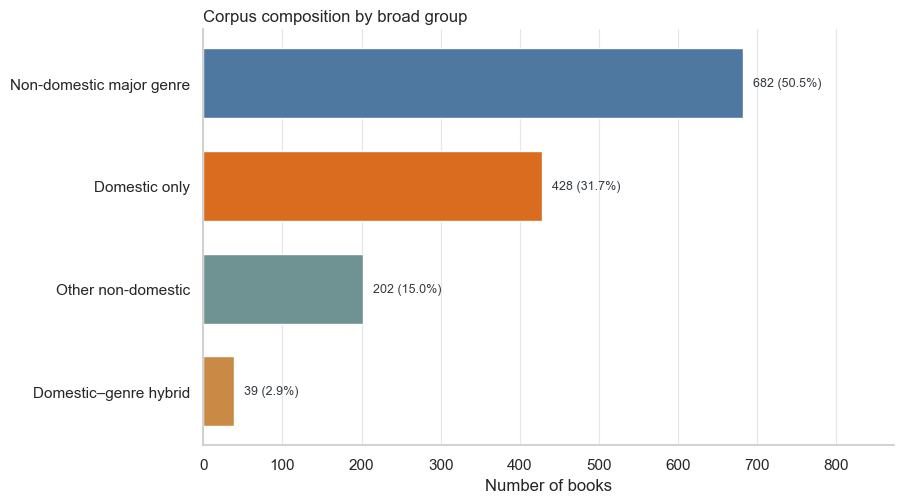

**Brief interpretation.** Non-domestic major genre is the largest mutually exclusive corpus group (682 books; 50.5%). This figure reports corpus composition only; interiority estimates are shown separately below.

In [ ]:
composition_data = publication_book_data.assign(
    broad_group_publication=publication_book_data["broad_group"].fillna("missing")
)
corpus_composition_summary = (
    composition_data.groupby("broad_group_publication", dropna=False)
    .agg(corpus_books=("gutenberg_id", "nunique"))
    .reset_index()
    .rename(columns={"broad_group_publication": "broad_group"})
)
corpus_composition_summary["group_label"] = corpus_composition_summary[
    "broad_group"
].map(BROAD_GROUP_LABELS)
corpus_composition_summary["corpus_pct"] = (
    corpus_composition_summary["corpus_books"]
    / publication_book_data["gutenberg_id"].nunique()
)
corpus_composition_summary = corpus_composition_summary.sort_values(
    "corpus_books", ascending=False
).reset_index(drop=True)
corpus_composition_summary.to_csv(
    PUBLICATION_TABLE_DIR / "figure1_corpus_composition.csv", index=False
)
display(
    corpus_composition_summary.style.format(
        {"corpus_pct": "{:.1%}"}
    )
)

plot_composition = corpus_composition_summary.copy()
y = np.arange(len(plot_composition))
fig, ax = plt.subplots(figsize=(9.2, 5.2))
bars = ax.barh(
    y,
    plot_composition["corpus_books"],
    color=[
        BROAD_GROUP_COLORS_PUBLICATION.get(group, RESIDUAL_GRAY)
        for group in plot_composition["broad_group"]
    ],
    height=0.68,
)
ax.set_yticks(y, plot_composition["group_label"])
ax.invert_yaxis()
ax.set_xlabel("Number of books")
ax.set_ylabel("")
ax.set_title("Corpus composition by broad group", loc="left")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
largest_count = max(plot_composition["corpus_books"])
ax.set_xlim(0, largest_count * 1.28)
for bar, row in zip(bars, plot_composition.itertuples()):
    ax.text(
        bar.get_width() + largest_count * 0.018,
        bar.get_y() + bar.get_height() / 2,
        f"{row.corpus_books:,} ({row.corpus_pct:.1%})",
        va="center",
        fontsize=9,
        color="#343A40",
    )
sns.despine(ax=ax)
plt.tight_layout()
save_figure(fig, PUBLICATION_FIGURE_DIR, "figure1_corpus_composition")
plt.show()

largest_group = plot_composition.iloc[0]
display(
    Markdown(
        f"**Brief interpretation.** {largest_group['group_label']} is the largest mutually exclusive corpus group "
        f"({largest_group['corpus_books']:,} books; {largest_group['corpus_pct']:.1%}). "
        "This figure reports corpus composition only; interiority estimates are shown separately below."
    )
)


#### Broad-group interiority summary


,broad_group,group_label,n_books,estimate,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,domestic_only,Domestic only,428,1.193,1.177,1.209,standard_n_ge_20,True,5000,20260731
1,domestic_and_genre,Domestic–genre hybrid,39,1.164,1.113,1.215,standard_n_ge_20,True,5000,20260731
2,major_genre_non_domestic,Non-domestic major genre,682,0.984,0.968,0.999,standard_n_ge_20,True,5000,20260731
3,other_non_domestic_non_major_genre,Other non-domestic,202,1.129,1.099,1.158,standard_n_ge_20,True,5000,20260731


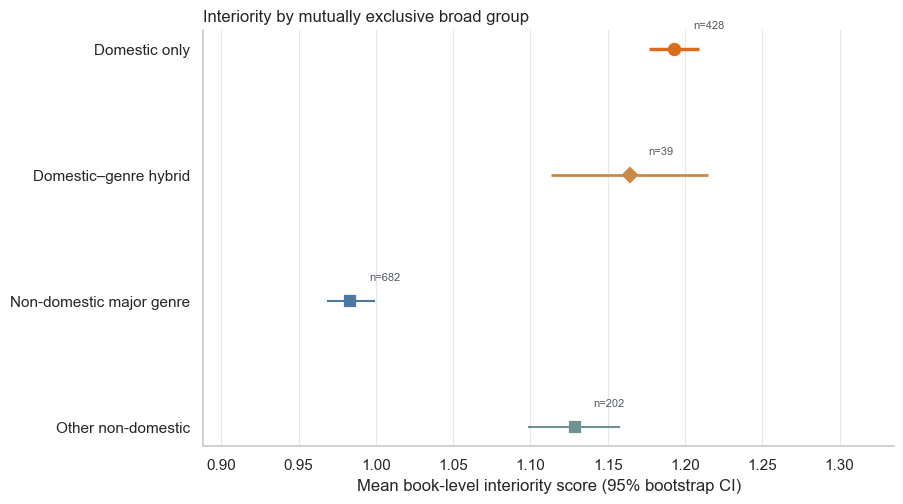

**Brief interpretation.** Domestic only has the highest descriptive book-level mean (1.19). The groups are mutually exclusive; intervals summarize book-level bootstrap variability rather than passage-level uncertainty.

In [ ]:
broad_group_summary_rows = []
composition_with_scores = publication_book_data.assign(
    broad_group_publication=publication_book_data["broad_group"].fillna("missing")
)
present_broad_groups = set(composition_with_scores["broad_group_publication"])
for broad_group in BROAD_GROUP_ORDER:
    if broad_group not in present_broad_groups:
        continue
    group_scores = composition_with_scores.loc[
        composition_with_scores["broad_group_publication"].eq(broad_group),
        "average_interiority_score",
    ]
    summary = bootstrap_mean_summary(
        group_scores,
        "broad_group_interiority",
        broad_group,
    )
    broad_group_summary_rows.append(
        {
            "broad_group": broad_group,
            "group_label": BROAD_GROUP_LABELS[broad_group],
            **summary,
        }
    )

broad_group_interiority_bootstrap = pd.DataFrame(broad_group_summary_rows)
broad_group_interiority_bootstrap.to_csv(
    PUBLICATION_TABLE_DIR / "figure1b_broad_group_interiority_bootstrap.csv",
    index=False,
)
display(
    broad_group_interiority_bootstrap.style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)

fig, ax = plt.subplots(figsize=(9.2, 5.2))
y = np.arange(len(broad_group_interiority_bootstrap))
for position, row in enumerate(broad_group_interiority_bootstrap.itertuples()):
    color = BROAD_GROUP_COLORS_PUBLICATION.get(row.broad_group, RESIDUAL_GRAY)
    is_domestic_only = row.broad_group == "domestic_only"
    is_domestic_hybrid = row.broad_group == "domestic_and_genre"
    marker = "o" if is_domestic_only else ("D" if is_domestic_hybrid else "s")
    linewidth = 2.5 if is_domestic_only else (2.0 if is_domestic_hybrid else 1.5)
    marker_size = 8 if is_domestic_only else 7
    marker_face = color if row.sample_status == "standard_n_ge_20" else "white"

    if row.ci_displayed:
        ax.hlines(
            position,
            row.ci_low,
            row.ci_high,
            color=color,
            linewidth=linewidth,
        )
        ax.plot(
            row.estimate,
            position,
            marker=marker,
            markersize=marker_size,
            markerfacecolor=marker_face,
            markeredgecolor=color,
            markeredgewidth=1.6,
            linestyle="none",
        )
    else:
        ax.plot(
            row.estimate,
            position,
            marker="x",
            markersize=8,
            color=color,
            markeredgewidth=1.8,
            linestyle="none",
        )
    ax.text(
        row.estimate + 0.012,
        position - 0.16,
        f"n={row.n_books}",
        fontsize=8,
        color="#555B61",
    )

ax.set_yticks(y, broad_group_interiority_bootstrap["group_label"])
ax.invert_yaxis()
ax.set_xlabel("Mean book-level interiority score (95% bootstrap CI)")
ax.set_ylabel("")
ax.set_title("Interiority by mutually exclusive broad group", loc="left")
finite_bounds = broad_group_interiority_bootstrap[["ci_low", "ci_high"]].to_numpy(float)
bound_min = np.nanmin(finite_bounds)
bound_max = np.nanmax(finite_bounds)
ax.set_xlim(bound_min - 0.08, bound_max + 0.12)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
sns.despine(ax=ax)
plt.tight_layout()
save_figure(fig, PUBLICATION_FIGURE_DIR, "figure1b_broad_group_interiority_summary")
plt.show()

highest_broad_group = broad_group_interiority_bootstrap.loc[
    broad_group_interiority_bootstrap["estimate"].idxmax()
]
display(
    Markdown(
        f"**Brief interpretation.** {highest_broad_group['group_label']} has the highest descriptive "
        f"book-level mean ({highest_broad_group['estimate']:.2f}). The groups are mutually exclusive; "
        "intervals summarize book-level bootstrap variability rather than passage-level uncertainty."
    )
)


#### Overall genre comparison


,group_column,group_label,n_books,estimate,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
0,is_domestic,Domestic,467,1.191,1.175,1.206,standard_n_ge_20,True,5000,20260731
1,is_gothic,Gothic,76,1.176,1.120,1.230,standard_n_ge_20,True,5000,20260731
2,is_canonical_author,Canonical author,221,1.144,1.114,1.175,standard_n_ge_20,True,5000,20260731
3,is_english_fiction_19c,"English fiction, 19th c.",112,1.103,1.072,1.133,standard_n_ge_20,True,5000,20260731
4,is_historical,Historical,164,1.016,0.987,1.046,standard_n_ge_20,True,5000,20260731
5,is_science_fiction,Science fiction,63,1.010,0.943,1.077,standard_n_ge_20,True,5000,20260731
6,is_detective_mystery,Detective / mystery,212,0.978,0.955,1.001,standard_n_ge_20,True,5000,20260731
7,is_adventure,Adventure,251,0.939,0.914,0.963,standard_n_ge_20,True,5000,20260731


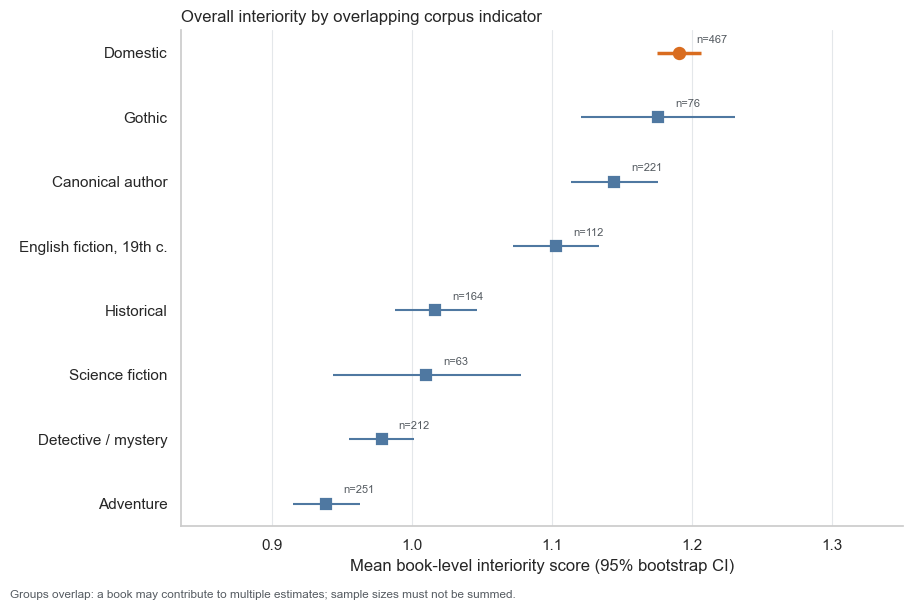

**Brief interpretation.** The highest descriptive mean is for Domestic (1.19); the lowest is for Adventure (0.94). Groups overlap, so these are not mutually exclusive corpus partitions.

In [ ]:
overall_genre_rows = []
for group_column in GENRE_COLUMNS:
    group_scores = publication_book_data.loc[
        publication_book_data[group_column].eq(1),
        "average_interiority_score",
    ]
    summary = bootstrap_mean_summary(
        group_scores,
        "overall_genre",
        group_column,
    )
    overall_genre_rows.append(
        {
            "group_column": group_column,
            "group_label": GENRE_LABELS[group_column],
            **summary,
        }
    )

overall_genre_bootstrap = pd.DataFrame(overall_genre_rows)
domestic_row = overall_genre_bootstrap.loc[
    overall_genre_bootstrap["group_column"].eq("is_domestic")
]
other_rows = overall_genre_bootstrap.loc[
    ~overall_genre_bootstrap["group_column"].eq("is_domestic")
].sort_values("estimate", ascending=False)
overall_genre_bootstrap = pd.concat(
    [domestic_row, other_rows], ignore_index=True
)
overall_genre_bootstrap.to_csv(
    PUBLICATION_TABLE_DIR / "figure2_overall_genre_bootstrap.csv",
    index=False,
)
display(
    overall_genre_bootstrap.style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)

fig, ax = plt.subplots(figsize=(9.2, 6.0))
y = np.arange(len(overall_genre_bootstrap))
for position, row in enumerate(overall_genre_bootstrap.itertuples()):
    is_domestic = row.group_column == "is_domestic"
    color = DOMESTIC_ORANGE if is_domestic else NONDOMESTIC_BLUE
    marker = "o" if is_domestic else "s"
    linewidth = 2.5 if is_domestic else 1.5
    marker_face = color if row.sample_status == "standard_n_ge_20" else "white"

    if row.ci_displayed:
        ax.hlines(position, row.ci_low, row.ci_high, color=color, linewidth=linewidth)
        ax.plot(
            row.estimate,
            position,
            marker=marker,
            markersize=8 if is_domestic else 7,
            markerfacecolor=marker_face,
            markeredgecolor=color,
            markeredgewidth=1.6,
            linestyle="none",
        )
    else:
        ax.plot(
            row.estimate,
            position,
            marker="x",
            markersize=8,
            color=color,
            markeredgewidth=1.8,
            linestyle="none",
        )
    ax.text(
        row.estimate + 0.012,
        position - 0.16,
        f"n={row.n_books}",
        fontsize=8,
        color="#555B61",
    )

ax.set_yticks(y, overall_genre_bootstrap["group_label"])
ax.invert_yaxis()
ax.set_xlabel("Mean book-level interiority score (95% bootstrap CI)")
ax.set_ylabel("")
ax.set_title("Overall interiority by overlapping corpus indicator", loc="left")
finite_bounds = overall_genre_bootstrap[["ci_low", "ci_high"]].to_numpy(float)
bound_min = np.nanmin(finite_bounds)
bound_max = np.nanmax(finite_bounds)
ax.set_xlim(bound_min - 0.08, bound_max + 0.12)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
sns.despine(ax=ax)
fig.text(
    0.01,
    -0.01,
    "Groups overlap: a book may contribute to multiple estimates; sample sizes must not be summed.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout()
save_figure(fig, PUBLICATION_FIGURE_DIR, "figure2_overall_genre_comparison")
plt.show()

highest_overall = overall_genre_bootstrap.loc[
    overall_genre_bootstrap["estimate"].idxmax()
]
lowest_overall = overall_genre_bootstrap.loc[
    overall_genre_bootstrap["estimate"].idxmin()
]
display(
    Markdown(
        f"**Brief interpretation.** The highest descriptive mean is for {highest_overall['group_label']} "
        f"({highest_overall['estimate']:.2f}); the lowest is for {lowest_overall['group_label']} "
        f"({lowest_overall['estimate']:.2f}). Groups overlap, so these are not mutually exclusive corpus partitions."
    )
)


#### Genre × period small multiples


**Valid book counts in every group × period cell**

publication_period,Pre-1840,1840–1899,1900+
group_label,,,
Domestic,19,190,258
Detective / mystery,0,49,163
Science fiction,4,19,40
Adventure,20,108,123
Gothic,21,30,25
Historical,23,75,66


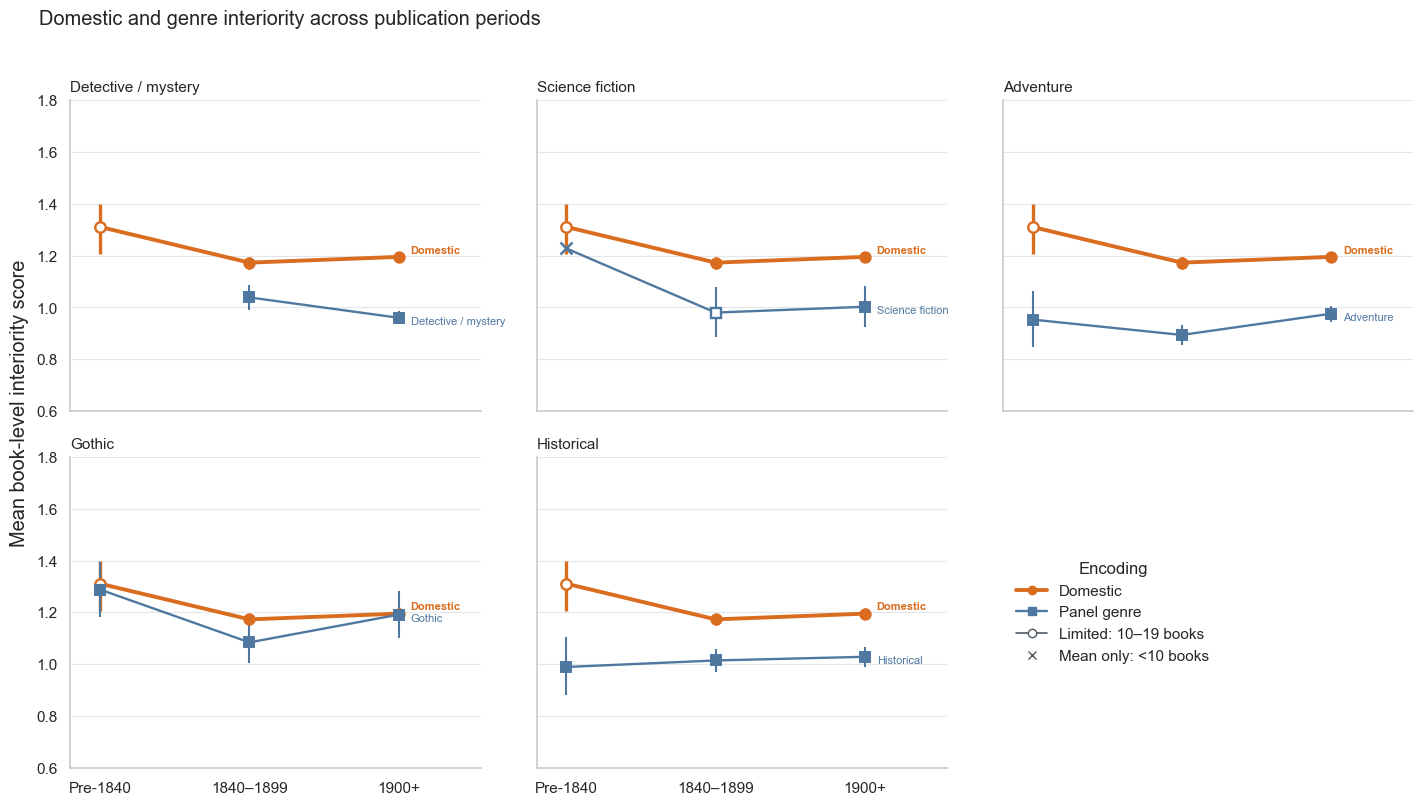

**Brief interpretation.** Period patterns vary across genres. The saved count table identifies 2 cell(s) with fewer than 10 valid books; those cells show a descriptive mean only or no estimate, without a displayed CI.

In [ ]:
genre_period_rows = []
comparison_groups = ["is_domestic", *SUBSTANTIVE_GENRES]
for group_column in comparison_groups:
    for period in PUBLICATION_PERIODS:
        cell_scores = publication_book_data.loc[
            publication_book_data[group_column].eq(1)
            & publication_book_data["publication_period"].eq(period),
            "average_interiority_score",
        ]
        summary = bootstrap_mean_summary(
            cell_scores,
            "genre_period",
            group_column,
            period,
        )
        genre_period_rows.append(
            {
                "group_column": group_column,
                "group_label": GENRE_LABELS[group_column],
                "publication_period": period,
                **summary,
            }
        )

genre_period_bootstrap = pd.DataFrame(genre_period_rows)
genre_period_bootstrap["publication_period"] = pd.Categorical(
    genre_period_bootstrap["publication_period"],
    categories=PUBLICATION_PERIODS,
    ordered=True,
)
genre_period_bootstrap = genre_period_bootstrap.sort_values(
    ["group_column", "publication_period"]
)
genre_period_bootstrap.to_csv(
    PUBLICATION_TABLE_DIR / "figure3_genre_period_bootstrap.csv",
    index=False,
)
genre_period_cell_counts = (
    genre_period_bootstrap.pivot(
        index="group_label",
        columns="publication_period",
        values="n_books",
    )
    .reindex(
        index=[GENRE_LABELS[column] for column in comparison_groups],
        columns=PUBLICATION_PERIODS,
    )
    .fillna(0)
    .astype(int)
)
genre_period_cell_counts.to_csv(
    PUBLICATION_TABLE_DIR / "figure3_genre_period_cell_counts.csv"
)
display(Markdown("**Valid book counts in every group × period cell**"))
display(genre_period_cell_counts)

finite_y = genre_period_bootstrap[
    ["estimate", "ci_low", "ci_high"]
].to_numpy(float)
y_min = np.floor((np.nanmin(finite_y) - 0.08) * 10) / 10
y_max = np.ceil((np.nanmax(finite_y) + 0.08) * 10) / 10


fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.2), sharex=True, sharey=True)
period_x = np.arange(len(PUBLICATION_PERIODS))
for ax, genre_column in zip(axes.flat[:5], SUBSTANTIVE_GENRES):
    domestic_series = genre_period_bootstrap.loc[
        genre_period_bootstrap["group_column"].eq("is_domestic")
    ].set_index("publication_period").reindex(PUBLICATION_PERIODS)
    genre_series = genre_period_bootstrap.loc[
        genre_period_bootstrap["group_column"].eq(genre_column)
    ].set_index("publication_period").reindex(PUBLICATION_PERIODS)

    ax.plot(
        period_x,
        domestic_series["estimate"],
        color=DOMESTIC_ORANGE,
        linewidth=2.8,
        zorder=2,
    )
    ax.plot(
        period_x,
        genre_series["estimate"],
        color=NONDOMESTIC_BLUE,
        linewidth=1.7,
        zorder=2,
    )
    for x_value, (_, row) in zip(period_x, domestic_series.iterrows()):
        if pd.notna(row["estimate"]):
            draw_period_estimate(
                ax, x_value, row, DOMESTIC_ORANGE, "o", domestic=True
            )
    for x_value, (_, row) in zip(period_x, genre_series.iterrows()):
        if pd.notna(row["estimate"]):
            draw_period_estimate(
                ax, x_value, row, NONDOMESTIC_BLUE, "s", domestic=False
            )

    last_domestic = domestic_series["estimate"].dropna()
    last_genre = genre_series["estimate"].dropna()
    if len(last_domestic):
        ax.text(
            2.08,
            last_domestic.iloc[-1] + 0.015,
            "Domestic",
            color=DOMESTIC_ORANGE,
            fontsize=8,
            fontweight="bold",
        )
    if len(last_genre):
        ax.text(
            2.08,
            last_genre.iloc[-1] - 0.025,
            GENRE_LABELS[genre_column],
            color=NONDOMESTIC_BLUE,
            fontsize=8,
        )
    ax.set_title(GENRE_LABELS[genre_column], loc="left", fontsize=11)
    ax.set_xticks(period_x, PUBLICATION_PERIODS)
    ax.set_xlim(-0.2, 2.55)
    ax.set_ylim(y_min, y_max)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color="#E4E7EA", linewidth=0.8)
    sns.despine(ax=ax)

axes.flat[5].axis("off")
status_handles = [
    Line2D([0], [0], color=DOMESTIC_ORANGE, marker="o", linewidth=2.8, label="Domestic"),
    Line2D([0], [0], color=NONDOMESTIC_BLUE, marker="s", linewidth=1.7, label="Panel genre"),
    Line2D([0], [0], color=NONDOMESTIC_DARK, marker="o", markerfacecolor="white", linewidth=1.2, label="Limited: 10–19 books"),
    Line2D([0], [0], color=NONDOMESTIC_DARK, marker="x", linewidth=0, label="Mean only: <10 books"),
]
axes.flat[5].legend(
    handles=status_handles,
    frameon=False,
    loc="center left",
    title="Encoding",
)
fig.supylabel("Mean book-level interiority score")
fig.suptitle("Domestic and genre interiority across publication periods", x=0.04, ha="left")
plt.tight_layout(rect=[0, 0, 1, 0.96])
save_figure(fig, PUBLICATION_FIGURE_DIR, "figure3_genre_period_small_multiples")
plt.show()

sparse_cells = genre_period_bootstrap.loc[
    genre_period_bootstrap["n_books"].lt(10)
]
display(
    Markdown(
        f"**Brief interpretation.** Period patterns vary across genres. The saved count table identifies "
        f"{len(sparse_cells)} cell(s) with fewer than 10 valid books; those cells show a descriptive mean only or no estimate, without a displayed CI."
    )
)


#### Genre difference from Domestic heatmap


,genre_column,genre_label,publication_period,n_genre,n_domestic,genre_mean,domestic_mean,difference,ci_low,ci_high,sample_status,ci_displayed,bootstrap_repetitions,bootstrap_seed
6,is_adventure,Adventure,Pre-1840,20,19,0.953,1.311,-0.358,-0.498,-0.208,limited_n_10_19,True,5000,20260731
7,is_adventure,Adventure,1840–1899,108,190,0.894,1.173,-0.279,-0.324,-0.235,standard_n_ge_20,True,5000,20260731
8,is_adventure,Adventure,1900+,123,258,0.976,1.195,-0.219,-0.256,-0.183,standard_n_ge_20,True,5000,20260731
0,is_detective_mystery,Detective / mystery,Pre-1840,0,19,nan,1.311,+nan,+nan,+nan,no_data,False,5000,20260731
1,is_detective_mystery,Detective / mystery,1840–1899,49,190,1.039,1.173,-0.134,-0.189,-0.080,standard_n_ge_20,True,5000,20260731
2,is_detective_mystery,Detective / mystery,1900+,163,258,0.960,1.195,-0.235,-0.269,-0.201,standard_n_ge_20,True,5000,20260731
9,is_gothic,Gothic,Pre-1840,21,19,1.288,1.311,-0.023,-0.157,+0.120,limited_n_10_19,True,5000,20260731
10,is_gothic,Gothic,1840–1899,30,190,1.084,1.173,-0.089,-0.172,-0.002,standard_n_ge_20,True,5000,20260731
11,is_gothic,Gothic,1900+,25,258,1.191,1.195,-0.004,-0.093,+0.089,standard_n_ge_20,True,5000,20260731
12,is_historical,Historical,Pre-1840,23,19,0.989,1.311,-0.321,-0.459,-0.172,limited_n_10_19,True,5000,20260731


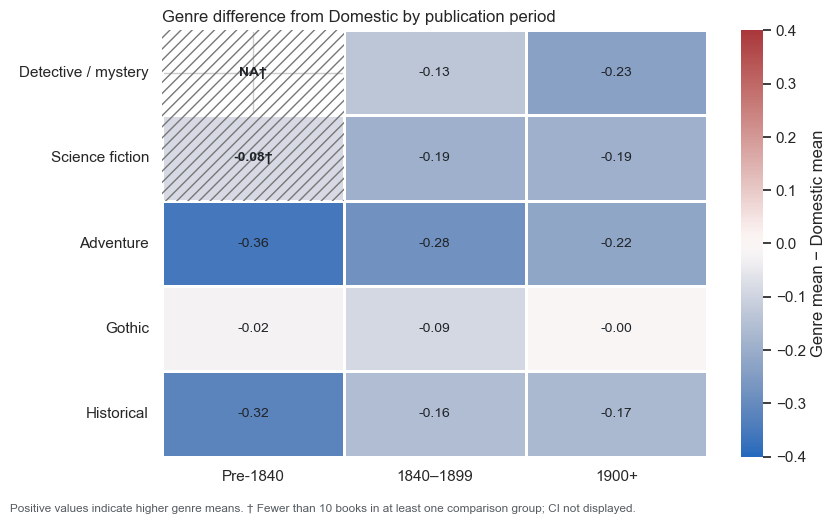

**Brief interpretation.** Among estimable cells, 0 genre-period means are above Domestic and 14 are below. 2 comparison(s) have fewer than 10 books in at least one group and are marked as descriptive only.

In [ ]:
difference_rows = []
for genre_column in SUBSTANTIVE_GENRES:
    for period in PUBLICATION_PERIODS:
        genre_scores = publication_book_data.loc[
            publication_book_data[genre_column].eq(1)
            & publication_book_data["publication_period"].eq(period),
            "average_interiority_score",
        ]
        domestic_scores = publication_book_data.loc[
            publication_book_data["is_domestic"].eq(1)
            & publication_book_data["publication_period"].eq(period),
            "average_interiority_score",
        ]
        summary = bootstrap_difference_summary(
            genre_scores,
            domestic_scores,
            "genre_minus_domestic",
            genre_column,
            period,
        )
        difference_rows.append(
            {
                "genre_column": genre_column,
                "genre_label": GENRE_LABELS[genre_column],
                "publication_period": period,
                **summary,
            }
        )

genre_domestic_difference_bootstrap = pd.DataFrame(difference_rows)
genre_domestic_difference_bootstrap["publication_period"] = pd.Categorical(
    genre_domestic_difference_bootstrap["publication_period"],
    categories=PUBLICATION_PERIODS,
    ordered=True,
)
genre_domestic_difference_bootstrap = genre_domestic_difference_bootstrap.sort_values(
    ["genre_column", "publication_period"]
)
genre_domestic_difference_bootstrap.to_csv(
    PUBLICATION_TABLE_DIR / "figure4_5_genre_minus_domestic_bootstrap.csv",
    index=False,
)
display(
    genre_domestic_difference_bootstrap.style.format(
        {
            "genre_mean": "{:.3f}",
            "domestic_mean": "{:.3f}",
            "difference": "{:+.3f}",
            "ci_low": "{:+.3f}",
            "ci_high": "{:+.3f}",
        }
    )
)

genre_order = [GENRE_LABELS[column] for column in SUBSTANTIVE_GENRES]
difference_matrix = (
    genre_domestic_difference_bootstrap.pivot(
        index="genre_label",
        columns="publication_period",
        values="difference",
    )
    .reindex(index=genre_order, columns=PUBLICATION_PERIODS)
)
sparse_matrix = (
    genre_domestic_difference_bootstrap.assign(
        sparse=lambda frame: frame[["n_genre", "n_domestic"]].min(axis=1).lt(10)
    )
    .pivot(
        index="genre_label",
        columns="publication_period",
        values="sparse",
    )
    .reindex(index=genre_order, columns=PUBLICATION_PERIODS)
    .fillna(True)
)
finite_differences = difference_matrix.to_numpy(float)
max_abs_difference = np.nanmax(np.abs(finite_differences))
heatmap_limit = max(0.1, np.ceil(max_abs_difference * 10) / 10)

fig, ax = plt.subplots(figsize=(8.6, 5.1))
sns.heatmap(
    difference_matrix,
    cmap="vlag",
    center=0,
    vmin=-heatmap_limit,
    vmax=heatmap_limit,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={"label": "Genre mean − Domestic mean"},
    annot=False,
    ax=ax,
)
for row_index, genre_label in enumerate(genre_order):
    for column_index, period in enumerate(PUBLICATION_PERIODS):
        value = difference_matrix.loc[genre_label, period]
        sparse = bool(sparse_matrix.loc[genre_label, period])
        label = "NA†" if pd.isna(value) else f"{value:+.2f}{'†' if sparse else ''}"
        ax.text(
            column_index + 0.5,
            row_index + 0.5,
            label,
            ha="center",
            va="center",
            fontsize=10,
            color="#202428",
            fontweight="bold" if sparse else "normal",
        )
        if sparse:
            ax.add_patch(
                Rectangle(
                    (column_index, row_index),
                    1,
                    1,
                    fill=False,
                    hatch="///",
                    edgecolor="#777777",
                    linewidth=0,
                )
            )
ax.set_title("Genre difference from Domestic by publication period", loc="left")
ax.set_xlabel("")
ax.set_ylabel("")
fig.text(
    0.01,
    -0.02,
    "Positive values indicate higher genre means. † Fewer than 10 books in at least one comparison group; CI not displayed.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout()
save_figure(fig, PUBLICATION_FIGURE_DIR, "figure4_genre_minus_domestic_heatmap")
plt.show()

finite_difference_rows = genre_domestic_difference_bootstrap.dropna(
    subset=["difference"]
)
positive_cells = int(finite_difference_rows["difference"].gt(0).sum())
negative_cells = int(finite_difference_rows["difference"].lt(0).sum())
sparse_comparisons = int(
    genre_domestic_difference_bootstrap[["n_genre", "n_domestic"]]
    .min(axis=1)
    .lt(10)
    .sum()
)
display(
    Markdown(
        f"**Brief interpretation.** Among estimable cells, {positive_cells} genre-period means are above "
        f"Domestic and {negative_cells} are below. {sparse_comparisons} comparison(s) have fewer than 10 books "
        "in at least one group and are marked as descriptive only."
    )
)


#### Mean-difference dot plot


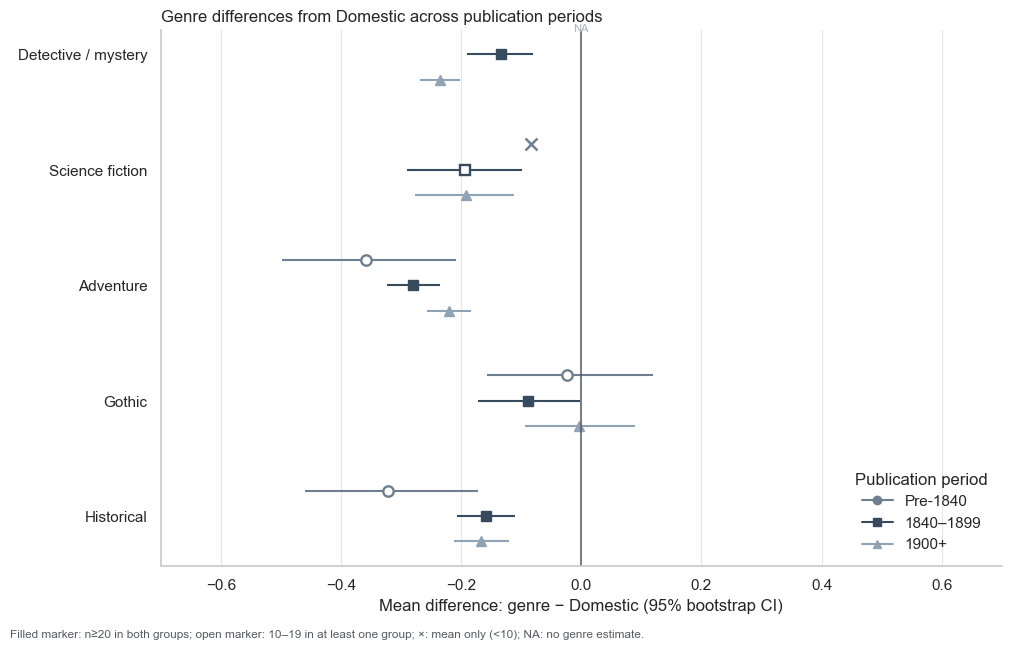

**Brief interpretation.** The plot emphasizes direction and bootstrap interval width. 2 displayed interval(s) span zero; this is a descriptive summary of book-level bootstrap variability, not a causal or formal significance claim.

In [ ]:
period_offsets = {
    "Pre-1840": -0.22,
    "1840–1899": 0.0,
    "1900+": 0.22,
}

fig, ax = plt.subplots(figsize=(10.2, 6.4))
y_base = {genre: index for index, genre in enumerate(genre_order)}
for row in genre_domestic_difference_bootstrap.itertuples():
    y_value = y_base[row.genre_label] + period_offsets[str(row.publication_period)]
    period = str(row.publication_period)
    color = PERIOD_COLORS[period]
    marker = PERIOD_MARKERS[period]

    if pd.isna(row.difference):
        ax.text(
            0,
            y_value,
            "NA",
            ha="center",
            va="center",
            fontsize=8,
            color=RESIDUAL_GRAY,
        )
    elif row.sample_status == "standard_n_ge_20":
        ax.hlines(y_value, row.ci_low, row.ci_high, color=color, linewidth=1.5)
        ax.plot(
            row.difference,
            y_value,
            marker=marker,
            markersize=7.5,
            markerfacecolor=color,
            markeredgecolor=color,
            linestyle="none",
        )
    elif row.sample_status == "limited_n_10_19":
        ax.hlines(y_value, row.ci_low, row.ci_high, color=color, linewidth=1.5)
        ax.plot(
            row.difference,
            y_value,
            marker=marker,
            markersize=7.5,
            markerfacecolor="white",
            markeredgecolor=color,
            markeredgewidth=1.7,
            linestyle="none",
        )
    else:
        ax.plot(
            row.difference,
            y_value,
            marker="x",
            markersize=8,
            color=color,
            markeredgewidth=1.8,
            linestyle="none",
        )

ax.axvline(0, color="#555B61", linewidth=1.1)
ax.set_yticks(range(len(genre_order)), genre_order)
ax.invert_yaxis()
ax.set_xlabel("Mean difference: genre − Domestic (95% bootstrap CI)")
ax.set_ylabel("")
ax.set_title("Genre differences from Domestic across publication periods", loc="left")
finite_ci = genre_domestic_difference_bootstrap[
    ["difference", "ci_low", "ci_high"]
].to_numpy(float)
difference_limit = np.nanmax(np.abs(finite_ci))
x_limit = np.ceil((difference_limit + 0.04) * 10) / 10
ax.set_xlim(-x_limit, x_limit)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
sns.despine(ax=ax)

period_handles = [
    Line2D(
        [0], [0],
        color=PERIOD_COLORS[period],
        marker=PERIOD_MARKERS[period],
        linewidth=1.5,
        label=period,
    )
    for period in PUBLICATION_PERIODS
]
ax.legend(
    handles=period_handles,
    title="Publication period",
    frameon=False,
    loc="lower right",
)
fig.text(
    0.01,
    -0.01,
    "Filled marker: n≥20 in both groups; open marker: 10–19 in at least one group; ×: mean only (<10); NA: no genre estimate.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout()
save_figure(fig, PUBLICATION_FIGURE_DIR, "figure5_genre_minus_domestic_dotplot")
plt.show()

displayed_intervals = genre_domestic_difference_bootstrap.loc[
    genre_domestic_difference_bootstrap["ci_displayed"]
]
intervals_crossing_zero = int(
    (
        displayed_intervals["ci_low"].le(0)
        & displayed_intervals["ci_high"].ge(0)
    ).sum()
)
display(
    Markdown(
        f"**Brief interpretation.** The plot emphasizes direction and bootstrap interval width. "
        f"{intervals_crossing_zero} displayed interval(s) span zero; this is a descriptive summary of "
        "book-level bootstrap variability, not a causal or formal significance claim."
    )
)


#### Saved publication outputs

Canonical paper figures are saved as 300-dpi PNG files and vector PDF files in `analysis/figures/`. Supporting descriptive figures and tables, including summarized plotting datasets, bootstrap bounds, cell sample sizes, and display-status fields, are saved under `analysis/outputs/descriptive/`.


### Quotation metrics by broad-group analysis and historical period

These exploratory comparisons use one observation per book and the mutually exclusive `broad_group_analysis` categories.


#### Overall broad-group-analysis quote-metric summary

In [ ]:
QUOTE_METRICS = [
    "overall_quote_share",
    "narration_quotation_interiority_gap",
    "narration_quotation_high_rate_gap",
    "high_narration_enrichment",
]
QUOTE_METRIC_LABELS = {
    "overall_quote_share": "Overall quote share",
    "narration_quotation_interiority_gap": "Narration − quotation interiority",
    "narration_quotation_high_rate_gap": "Narration − quotation HIGH rate",
    "high_narration_enrichment": "HIGH narration enrichment",
}
ZERO_REFERENCE_METRICS = {
    "narration_quotation_interiority_gap",
    "narration_quotation_high_rate_gap",
    "high_narration_enrichment",
}

quote_book_data = (
    book_summary_analysis
    .drop_duplicates("gutenberg_id")
    .assign(
        broad_group_analysis_plot=lambda frame: frame["broad_group_analysis"].fillna("missing")
    )
    .copy()
)
if len(quote_book_data) != book_summary_analysis["gutenberg_id"].nunique():
    raise ValueError("Quotation comparisons require exactly one row per book.")

quote_broad_group_analysis_order = [
    group
    for group in BROAD_GROUP_ANALYSIS_ORDER
    if group != "missing"
    and group in set(quote_book_data["broad_group_analysis_plot"])
]

quote_group_rows = []
for metric in QUOTE_METRICS:
    for group in quote_broad_group_analysis_order:
        values = quote_book_data.loc[
            quote_book_data["broad_group_analysis_plot"].eq(group),
            metric,
        ]
        summary = bootstrap_mean_summary(
            values,
            "quote_metric_broad_group_analysis",
            metric,
            group,
        )
        quote_group_rows.append(
            {
                "metric": metric,
                "metric_label": QUOTE_METRIC_LABELS[metric],
                "broad_group_analysis": group,
                "group_label": BROAD_GROUP_ANALYSIS_LABELS[group],
                **summary,
            }
        )

quote_metric_broad_group_bootstrap = pd.DataFrame(quote_group_rows)
quote_metric_broad_group_bootstrap["broad_group_analysis"] = pd.Categorical(
    quote_metric_broad_group_bootstrap["broad_group_analysis"],
    categories=quote_broad_group_analysis_order,
    ordered=True,
)
quote_metric_broad_group_bootstrap = (
    quote_metric_broad_group_bootstrap
    .sort_values(["metric", "broad_group_analysis"])
    .reset_index(drop=True)
)
quote_metric_broad_group_bootstrap.to_csv(
    PUBLICATION_TABLE_DIR / "section8_quote_metric_broad_group_bootstrap.csv",
    index=False,
)

# Supporting historical-period estimates use the same book-level bootstrap.
quote_group_period_rows = []
for metric in QUOTE_METRICS:
    for group in quote_broad_group_analysis_order:
        for period in TIME_PERIOD_ORDER:
            values = quote_book_data.loc[
                quote_book_data["broad_group_analysis_plot"].eq(group)
                & quote_book_data["time_period"].eq(period),
                metric,
            ]
            summary = bootstrap_mean_summary(
                values,
                "quote_metric_broad_group_analysis_period",
                metric,
                group,
                period,
            )
            quote_group_period_rows.append(
                {
                    "metric": metric,
                    "metric_label": QUOTE_METRIC_LABELS[metric],
                    "broad_group_analysis": group,
                    "group_label": BROAD_GROUP_ANALYSIS_LABELS[group],
                    "time_period": period,
                    **summary,
                }
            )

quote_metric_broad_group_period_bootstrap = pd.DataFrame(
    quote_group_period_rows
)
quote_metric_broad_group_period_bootstrap.to_csv(
    PUBLICATION_TABLE_DIR
    / "section8_quote_metric_broad_group_period_bootstrap.csv",
    index=False,
)

display(
    quote_metric_broad_group_bootstrap[
        [
            "metric_label",
            "group_label",
            "n_books",
            "estimate",
            "ci_low",
            "ci_high",
        ]
    ].style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)
display(Markdown("**Supporting broad-group-analysis × historical-period estimates**"))
display(
    quote_metric_broad_group_period_bootstrap[
        [
            "metric_label",
            "group_label",
            "time_period",
            "n_books",
            "estimate",
            "ci_low",
            "ci_high",
            "sample_status",
        ]
    ].style.format(
        {
            "estimate": "{:.3f}",
            "ci_low": "{:.3f}",
            "ci_high": "{:.3f}",
        }
    )
)

,metric_label,group_label,n_books,estimate,ci_low,ci_high
0,HIGH narration enrichment,All domestic,467,0.110,0.102,0.118
1,HIGH narration enrichment,Non-domestic major genre,682,0.076,0.067,0.086
2,HIGH narration enrichment,Other non-domestic,202,0.058,0.044,0.072
3,Narration − quotation HIGH rate,All domestic,446,0.214,0.198,0.231
4,Narration − quotation HIGH rate,Non-domestic major genre,630,0.107,0.094,0.119
5,Narration − quotation HIGH rate,Other non-domestic,177,0.105,0.082,0.129
6,Narration − quotation interiority,All domestic,446,0.212,0.189,0.235
7,Narration − quotation interiority,Non-domestic major genre,630,0.088,0.067,0.109
8,Narration − quotation interiority,Other non-domestic,177,0.066,0.029,0.103
9,Overall quote share,All domestic,467,0.431,0.420,0.441


**Supporting broad-group-analysis × historical-period estimates**

,metric_label,group_label,time_period,n_books,estimate,ci_low,ci_high,sample_status
0,Overall quote share,All domestic,<1840,19,0.373,0.306,0.437,limited_n_10_19
1,Overall quote share,All domestic,1840-1899,190,0.449,0.434,0.464,standard_n_ge_20
2,Overall quote share,All domestic,1900+,258,0.421,0.406,0.436,standard_n_ge_20
3,Overall quote share,Non-domestic major genre,<1840,59,0.345,0.294,0.395,standard_n_ge_20
4,Overall quote share,Non-domestic major genre,1840-1899,253,0.404,0.387,0.422,standard_n_ge_20
5,Overall quote share,Non-domestic major genre,1900+,370,0.429,0.415,0.443,standard_n_ge_20
6,Overall quote share,Other non-domestic,<1840,31,0.369,0.300,0.433,standard_n_ge_20
7,Overall quote share,Other non-domestic,1840-1899,115,0.423,0.397,0.447,standard_n_ge_20
8,Overall quote share,Other non-domestic,1900+,56,0.376,0.338,0.412,standard_n_ge_20
9,Narration − quotation interiority,All domestic,<1840,17,0.036,-0.093,0.158,limited_n_10_19


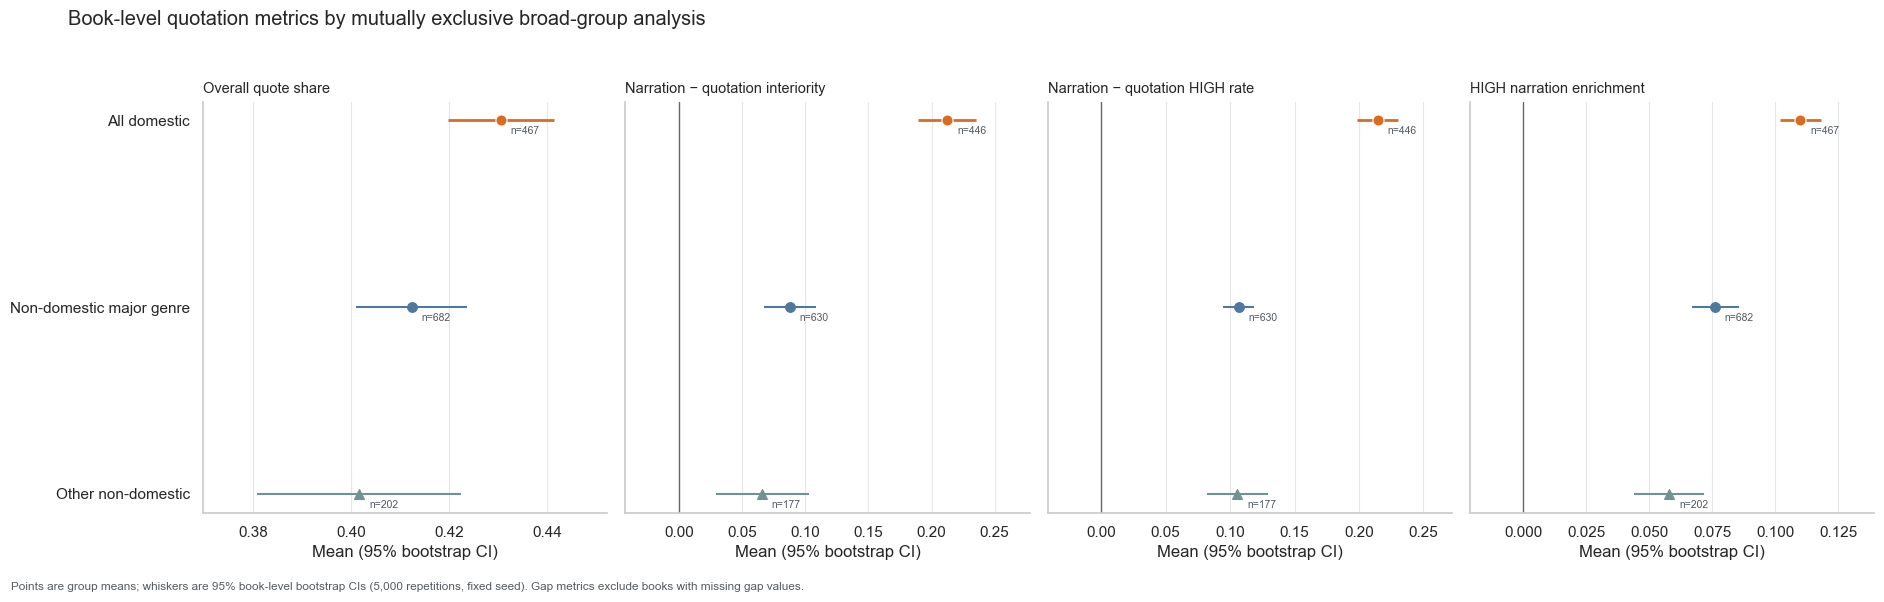

**Brief interpretation.** All domestic has the highest descriptive mean overall quote share (0.43). The gap panels describe book-level contrasts and should be read alongside their valid-book counts.

In [ ]:
fig, axes = plt.subplots(
    1,
    len(QUOTE_METRICS),
    figsize=(19, 5.8),
    sharey=True,
)
y_positions = np.arange(len(quote_broad_group_analysis_order))

for panel_index, (ax, metric) in enumerate(zip(axes, QUOTE_METRICS)):
    panel = (
        quote_metric_broad_group_bootstrap.loc[
            quote_metric_broad_group_bootstrap["metric"].eq(metric)
        ]
        .set_index("broad_group_analysis")
        .reindex(quote_broad_group_analysis_order)
    )

    if metric in ZERO_REFERENCE_METRICS:
        ax.axvline(0, color="#626970", linewidth=1.0, zorder=1)

    for y_position, (group, row) in zip(y_positions, panel.iterrows()):
        color = BROAD_GROUP_ANALYSIS_COLORS[group]
        marker = BROAD_GROUP_ANALYSIS_MARKERS[group]
        ax.hlines(
            y_position,
            row["ci_low"],
            row["ci_high"],
            color=color,
            linewidth=2.0 if group == "all_domestic" else 1.5,
            zorder=2,
        )
        ax.plot(
            row["estimate"],
            y_position,
            marker=marker,
            markersize=8 if group == "all_domestic" else 7,
            markerfacecolor=color,
            markeredgecolor="white" if group == "all_domestic" else color,
            markeredgewidth=0.8,
            linestyle="none",
            zorder=3,
        )
        ax.annotate(
            f"n={int(row['n_books'])}",
            (row["estimate"], y_position),
            xytext=(7, -10),
            textcoords="offset points",
            fontsize=7.5,
            color="#555B61",
        )

    ax.set_title(QUOTE_METRIC_LABELS[metric], loc="left", fontsize=10.5)
    ax.set_xlabel("Mean (95% bootstrap CI)")
    ax.set_yticks(
        y_positions,
        [BROAD_GROUP_ANALYSIS_LABELS[group] for group in quote_broad_group_analysis_order],
    )
    if panel_index == 0:
        ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
    ax.margins(x=0.18)
    if panel_index > 0:
        ax.tick_params(axis="y", labelleft=False)
    sns.despine(ax=ax)

fig.suptitle(
    "Book-level quotation metrics by mutually exclusive broad-group analysis",
    x=0.04,
    ha="left",
)
fig.text(
    0.01,
    -0.02,
    "Points are group means; whiskers are 95% book-level bootstrap CIs (5,000 repetitions, fixed seed). "
    "Gap metrics exclude books with missing gap values.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_figure(
    fig,
    PUBLICATION_FIGURE_DIR,
    "section8_quote_metric_broad_group_summary",
)
plt.show()

overall_quote_panel = quote_metric_broad_group_bootstrap.loc[
    quote_metric_broad_group_bootstrap["metric"].eq("overall_quote_share")
]
highest_quote_group = overall_quote_panel.loc[
    overall_quote_panel["estimate"].idxmax()
]
display(
    Markdown(
        f"**Brief interpretation.** {highest_quote_group['group_label']} has the highest "
        f"descriptive mean overall quote share ({highest_quote_group['estimate']:.2f}). "
        "The gap panels describe book-level contrasts and should be read alongside their valid-book counts."
    )
)

#### Book-level metric distributions

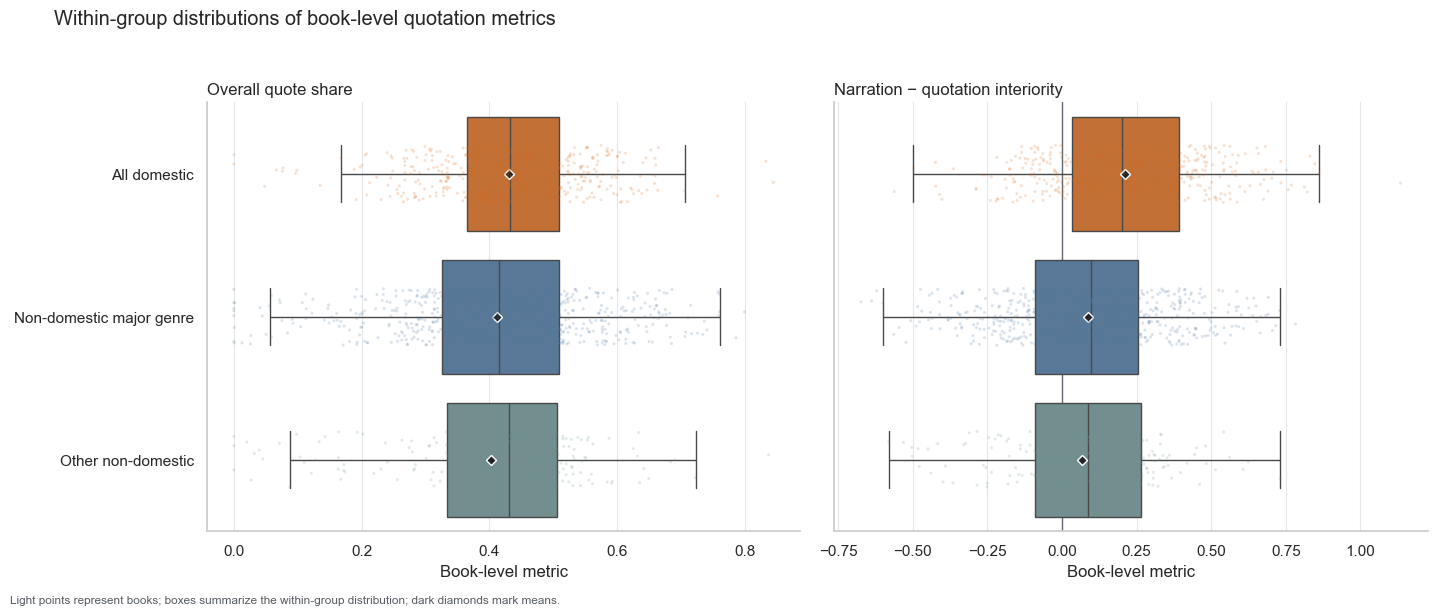

**Brief interpretation.** The point clouds show substantial within-group variation. Differences between the mean diamonds and boxplot medians indicate where skew or extreme books may affect a group mean.

In [ ]:
DISTRIBUTION_METRICS = [
    "overall_quote_share",
    "narration_quotation_interiority_gap",
]
quote_distribution_data = quote_book_data.loc[
    quote_book_data["broad_group_analysis_plot"].isin(quote_broad_group_analysis_order),
    ["gutenberg_id", "broad_group_analysis_plot", *DISTRIBUTION_METRICS],
].copy()
quote_distribution_data.to_csv(
    PUBLICATION_TABLE_DIR / "section8_quote_metric_distribution_data.csv",
    index=False,
)

distribution_palette = {
    group: BROAD_GROUP_ANALYSIS_COLORS[group]
    for group in quote_broad_group_analysis_order
}
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.0), sharey=True)

for panel_index, (ax, metric) in enumerate(zip(axes, DISTRIBUTION_METRICS)):
    metric_data = quote_distribution_data.dropna(subset=[metric])
    sns.boxplot(
        data=metric_data,
        y="broad_group_analysis_plot",
        x=metric,
        order=quote_broad_group_analysis_order,
        hue="broad_group_analysis_plot",
        hue_order=quote_broad_group_analysis_order,
        palette=distribution_palette,
        dodge=False,
        showfliers=False,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "#202428",
            "markeredgecolor": "white",
            "markersize": 5,
        },
        linewidth=1.0,
        legend=False,
        ax=ax,
    )
    sns.stripplot(
        data=metric_data,
        y="broad_group_analysis_plot",
        x=metric,
        order=quote_broad_group_analysis_order,
        hue="broad_group_analysis_plot",
        hue_order=quote_broad_group_analysis_order,
        palette=distribution_palette,
        dodge=False,
        jitter=0.20,
        size=2.2,
        alpha=0.20,
        linewidth=0,
        legend=False,
        ax=ax,
    )
    if metric in ZERO_REFERENCE_METRICS:
        ax.axvline(0, color="#626970", linewidth=1.0, zorder=1)
    ax.set_title(QUOTE_METRIC_LABELS[metric], loc="left")
    ax.set_xlabel("Book-level metric")
    ax.set_ylabel("")
    ax.set_yticks(
        np.arange(len(quote_broad_group_analysis_order)),
        [BROAD_GROUP_ANALYSIS_LABELS[group] for group in quote_broad_group_analysis_order],
    )
    if panel_index > 0:
        ax.tick_params(axis="y", labelleft=False)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#E4E7EA", linewidth=0.8)
    sns.despine(ax=ax)

fig.suptitle(
    "Within-group distributions of book-level quotation metrics",
    x=0.04,
    ha="left",
)
fig.text(
    0.01,
    -0.01,
    "Light points represent books; boxes summarize the within-group distribution; dark diamonds mark means.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_figure(
    fig,
    PUBLICATION_FIGURE_DIR,
    "section8_quote_metric_distributions",
)
plt.show()

distribution_mean_median = (
    quote_distribution_data.groupby("broad_group_analysis_plot", as_index=False)
    .agg(
        overall_quote_mean=("overall_quote_share", "mean"),
        overall_quote_median=("overall_quote_share", "median"),
        gap_mean=("narration_quotation_interiority_gap", "mean"),
        gap_median=("narration_quotation_interiority_gap", "median"),
    )
)
display(
    Markdown(
        "**Brief interpretation.** The point clouds show substantial within-group variation. "
        "Differences between the mean diamonds and boxplot medians indicate where skew or extreme books may affect a group mean."
    )
)

#### Quote metrics across historical periods

Each point is a mean of book-level metrics within a mutually exclusive broad-group-analysis × historical-period cell. Error bars are 95% book-level bootstrap confidence intervals (5,000 repetitions; fixed seed). Consistent with the notebook's sample-size rule, cells with fewer than 10 valid books show the descriptive mean without a confidence interval. Valid book counts for every cell are reported in the companion table.


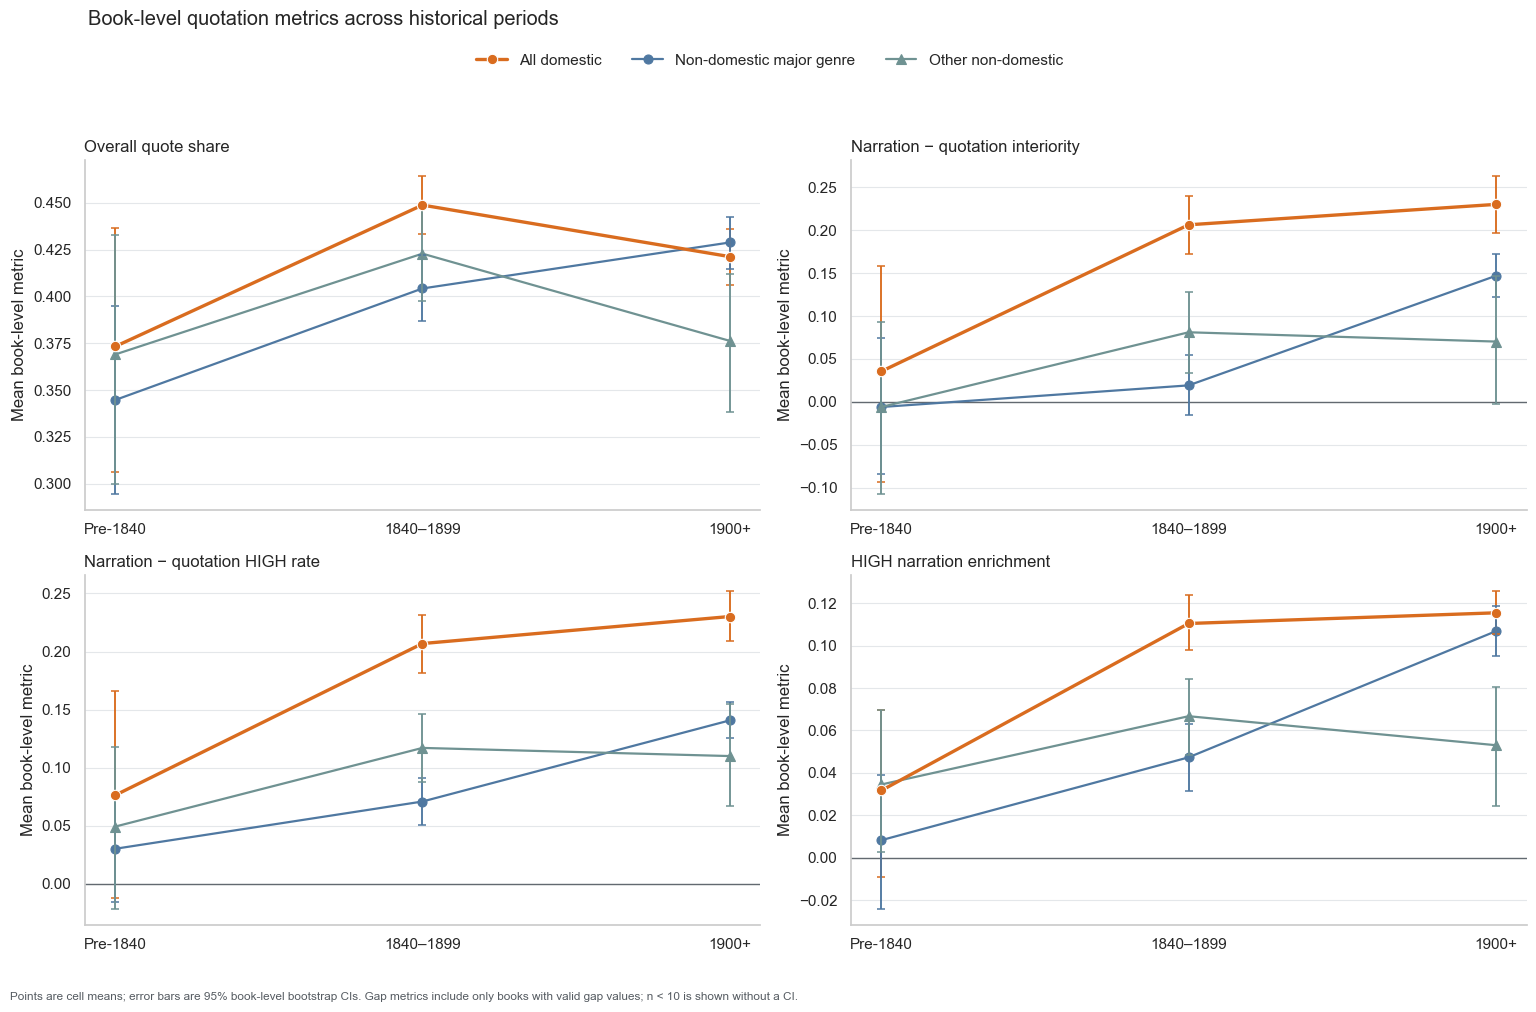

**Valid book counts by broad-group analysis and historical period**

**Brief interpretation.** The panels show descriptive changes in group means across the three periods. 0 of 36 cells contain fewer than 10 valid books and are therefore shown without a confidence interval; the count table should guide interpretation.

In [ ]:
QUOTE_PERIOD_DISPLAY_LABELS = {
    "<1840": "Pre-1840",
    "1840-1899": "1840–1899",
    "1900+": "1900+",
}

quote_metric_period_plot = quote_metric_broad_group_period_bootstrap.copy()
quote_metric_period_plot["time_period"] = pd.Categorical(
    quote_metric_period_plot["time_period"],
    categories=TIME_PERIOD_ORDER,
    ordered=True,
)
quote_metric_period_plot["historical_period"] = (
    quote_metric_period_plot["time_period"]
    .astype("object")
    .map(QUOTE_PERIOD_DISPLAY_LABELS)
)
quote_metric_period_plot["metric"] = pd.Categorical(
    quote_metric_period_plot["metric"],
    categories=QUOTE_METRICS,
    ordered=True,
)
quote_metric_period_plot["broad_group_analysis"] = pd.Categorical(
    quote_metric_period_plot["broad_group_analysis"],
    categories=quote_broad_group_analysis_order,
    ordered=True,
)
quote_metric_period_plot = quote_metric_period_plot.sort_values(
    ["metric", "broad_group_analysis", "time_period"]
).reset_index(drop=True)

quote_metric_period_plot.to_csv(
    PUBLICATION_TABLE_DIR / "section9_3_quote_metric_period_bootstrap.csv",
    index=False,
)

quote_metric_period_counts = quote_metric_period_plot[
    [
        "metric",
        "metric_label",
        "broad_group_analysis",
        "group_label",
        "historical_period",
        "n_books",
        "sample_status",
        "ci_displayed",
    ]
].copy()
quote_metric_period_counts.to_csv(
    PUBLICATION_TABLE_DIR / "section9_3_quote_metric_valid_book_counts.csv",
    index=False,
)

fig, axes = plt.subplots(2, 2, figsize=(15.5, 10.0))
axes = axes.ravel()
x_positions = np.arange(len(TIME_PERIOD_ORDER))

for ax, metric in zip(axes, QUOTE_METRICS):
    metric_panel = quote_metric_period_plot.loc[
        quote_metric_period_plot["metric"].eq(metric)
    ]

    if metric in ZERO_REFERENCE_METRICS:
        ax.axhline(0, color="#626970", linewidth=1.0, zorder=1)

    for group in quote_broad_group_analysis_order:
        group_panel = (
            metric_panel.loc[metric_panel["broad_group_analysis"].eq(group)]
            .set_index("time_period")
            .reindex(TIME_PERIOD_ORDER)
        )
        estimates = group_panel["estimate"].to_numpy(float)
        color = BROAD_GROUP_ANALYSIS_COLORS[group]
        marker = BROAD_GROUP_ANALYSIS_MARKERS[group]

        ax.plot(
            x_positions,
            estimates,
            color=color,
            marker=marker,
            markerfacecolor=color,
            markeredgecolor="white" if group == "all_domestic" else color,
            markeredgewidth=0.8,
            markersize=7.5 if group == "all_domestic" else 6.5,
            linewidth=2.4 if group == "all_domestic" else (
                2.0 if group == "domestic_and_genre" else 1.6
            ),
            label=BROAD_GROUP_ANALYSIS_LABELS[group],
            zorder=3 if group == "all_domestic" else 2,
        )

        ci_rows = group_panel["ci_displayed"].fillna(False).to_numpy(bool)
        for x_position, show_ci, estimate, ci_low, ci_high in zip(
            x_positions,
            ci_rows,
            estimates,
            group_panel["ci_low"].to_numpy(float),
            group_panel["ci_high"].to_numpy(float),
        ):
            if show_ci and np.isfinite([estimate, ci_low, ci_high]).all():
                ax.errorbar(
                    x_position,
                    estimate,
                    yerr=[[estimate - ci_low], [ci_high - estimate]],
                    fmt="none",
                    ecolor=color,
                    elinewidth=1.35,
                    capsize=3,
                    capthick=1.1,
                    zorder=2.5,
                )

    ax.set_title(QUOTE_METRIC_LABELS[metric], loc="left")
    ax.set_xticks(
        x_positions,
        [QUOTE_PERIOD_DISPLAY_LABELS[period] for period in TIME_PERIOD_ORDER],
    )
    ax.set_xlabel("")
    ax.set_ylabel("Mean book-level metric")
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color="#E4E7EA", linewidth=0.8)
    sns.despine(ax=ax)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=3,
    frameon=False,
)
fig.suptitle(
    "Book-level quotation metrics across historical periods",
    x=0.06,
    ha="left",
    y=0.995,
)
fig.text(
    0.01,
    0.005,
    "Points are cell means; error bars are 95% book-level bootstrap CIs. "
    "Gap metrics include only books with valid gap values; n < 10 is shown without a CI.",
    fontsize=8.5,
    color="#555B61",
)
plt.tight_layout(rect=[0, 0.035, 1, 0.92])
save_figure(
    fig,
    PUBLICATION_FIGURE_DIR,
    "section9_3_quote_metrics_by_historical_period",
)
plt.show()

display(Markdown("**Valid book counts by broad-group analysis and historical period**"))
quote_metric_period_count_table = (
    quote_metric_period_counts.pivot(
        index=["metric_label", "group_label"],
        columns="historical_period",
        values="n_books",
    )
    .reindex(
        pd.MultiIndex.from_product(
            [
                [QUOTE_METRIC_LABELS[metric] for metric in QUOTE_METRICS],
                [BROAD_GROUP_ANALYSIS_LABELS[group] for group in quote_broad_group_analysis_order],
            ],
            names=["metric_label", "group_label"],
        )
    )
    .reindex(
        columns=[QUOTE_PERIOD_DISPLAY_LABELS[period] for period in TIME_PERIOD_ORDER]
    )
)
display(quote_metric_period_count_table.style.format("{:.0f}"))

n_sparse_cells = int(quote_metric_period_plot["n_books"].lt(10).sum())
display(
    Markdown(
        f"**Brief interpretation.** The panels show descriptive changes in group means across "
        f"the three periods. {n_sparse_cells} of {len(quote_metric_period_plot)} cells contain fewer than 10 valid books and "
        "are therefore shown without a confidence interval; the count table should guide interpretation."
    )
)
